In [11]:
# Install necessary packages
if(!require(astsa)) install.packages("astsa")
if(!require(ggplot2)) install.packages("ggplot2")
if(!require(ggfortify)) install.packages("ggfortify")
if(!require(expsmooth)) install.packages("expsmooth")
if(!require(lmtest)) install.packages("lmtest")
if(!require(zoo)) install.packages("zoo")
if(!require(fpp2)) install.packages("fpp2")
if(!require(datasets)) install.packages("datasets") # Usually pre-installed
if(!require(readr)) install.packages("readr")
if(!require(dplyr)) install.packages("dplyr")
if(!require(quantmod)) install.packages("quantmod")
if(!require(vars)) install.packages("vars")
if(!require(rugarch)) install.packages("rugarch")
if(!require(forecast)) install.packages("forecast")
if(!require(tidyr)) install.packages("tidyr")
if(!require(abind)) install.packages("abind")
if(!require(reticulate)) install.packages("reticulate")
if(!require(tensorflow)) install.packages("tensorflow")
if(!require(keras)) install.packages("keras")
if(!require(patchwork)) install.packages("patchwork")
if(!require(stats)) install.packages("stats") # Usually pre-installed
if(!require(stats4)) install.packages("stats4") # Usually pre-installed
if(!require(lubridate)) install.packages("lubridate")
if(!require(prophet)) install.packages("prophet")

Loading required package: astsa

Loading required package: ggplot2

Loading required package: ggfortify

Loading required package: expsmooth

Loading required package: forecast

Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 

Registered S3 methods overwritten by 'forecast':
  method                 from     
  autoplot.Arima         ggfortify
  autoplot.acf           ggfortify
  autoplot.ar            ggfortify
  autoplot.bats          ggfortify
  autoplot.decomposed.ts ggfortify
  autoplot.ets           ggfortify
  autoplot.forecast      ggfortify
  autoplot.stl           ggfortify
  autoplot.ts            ggfortify
  fitted.ar              ggfortify
  fortify.ts             ggfortify
  residuals.ar           ggfortify


Attaching package: ‘forecast’


The following object is masked from ‘package:astsa’:

    gas


Loading required package: lmtest

Loading required package: zoo


Attaching package: ‘zoo’


The following objects are ma

In [12]:
# Load necessary libraries
library(astsa)
library(ggplot2)
library(ggfortify)
library(expsmooth)
library(lmtest)
library(zoo)
library(fpp2)
library(datasets)
library(readr)
library(dplyr)
library(quantmod)
library(vars)
library(rugarch)
library(forecast)
library(tidyr)
library(abind)
library(reticulate)
library(tensorflow)
library(keras)
library(patchwork)
library(stats)
library(stats4)
library(lubridate)
library(prophet)

In [13]:
# Read data from local

url <- "https://raw.githubusercontent.com/AungCN/TrafficFlowPrediction_PEMS08/main/traffic.csv"

# Use read.csv instead of read_csv with the correct arguments
traffic <- read.csv(url, header = TRUE, stringsAsFactors = FALSE)

#traffic <- read.table("https://github.com/AungCN/TrafficFlowPrediction_PEMS08/blob/main/traffic.csv", sep=',', header=T)
#View(traffic)
# Check the structure of the dataset
head(traffic)
summary(traffic)
str(traffic)

,timestep,location,flow,occupy,speed
,<int>,<int>,<dbl>,<dbl>,<dbl>
1,1,0,133,0.0603,65.8
2,1,1,210,0.0589,69.6
3,1,2,124,0.0358,65.8
4,1,3,145,0.0416,69.6
5,1,4,206,0.0493,69.4
6,1,5,58,0.0147,70.8


    timestep        location          flow            occupy       
 Min.   :    1   Min.   :  0.0   Min.   :   0.0   Min.   :0.00000  
 1st Qu.: 4465   1st Qu.: 42.0   1st Qu.: 110.0   1st Qu.:0.03570  
 Median : 8928   Median : 84.5   Median : 215.0   Median :0.06010  
 Mean   : 8928   Mean   : 84.5   Mean   : 230.7   Mean   :0.06507  
 3rd Qu.:13392   3rd Qu.:127.0   3rd Qu.: 334.0   3rd Qu.:0.08390  
 Max.   :17856   Max.   :169.0   Max.   :1147.0   Max.   :0.89550  
     speed      
 Min.   : 3.00  
 1st Qu.:62.60  
 Median :64.90  
 Mean   :63.76  
 3rd Qu.:67.40  
 Max.   :82.30  

'data.frame':	3035520 obs. of  5 variables:
 $ timestep: int  1 1 1 1 1 1 1 1 1 1 ...
 $ location: int  0 1 2 3 4 5 6 7 8 9 ...
 $ flow    : num  133 210 124 145 206 58 248 117 44 256 ...
 $ occupy  : num  0.0603 0.0589 0.0358 0.0416 0.0493 0.0147 0.0732 0.0678 0.0295 0.0385 ...
 $ speed   : num  65.8 69.6 65.8 69.6 69.4 70.8 68.9 64.9 68.4 68.9 ...


In [27]:
library(tseries)

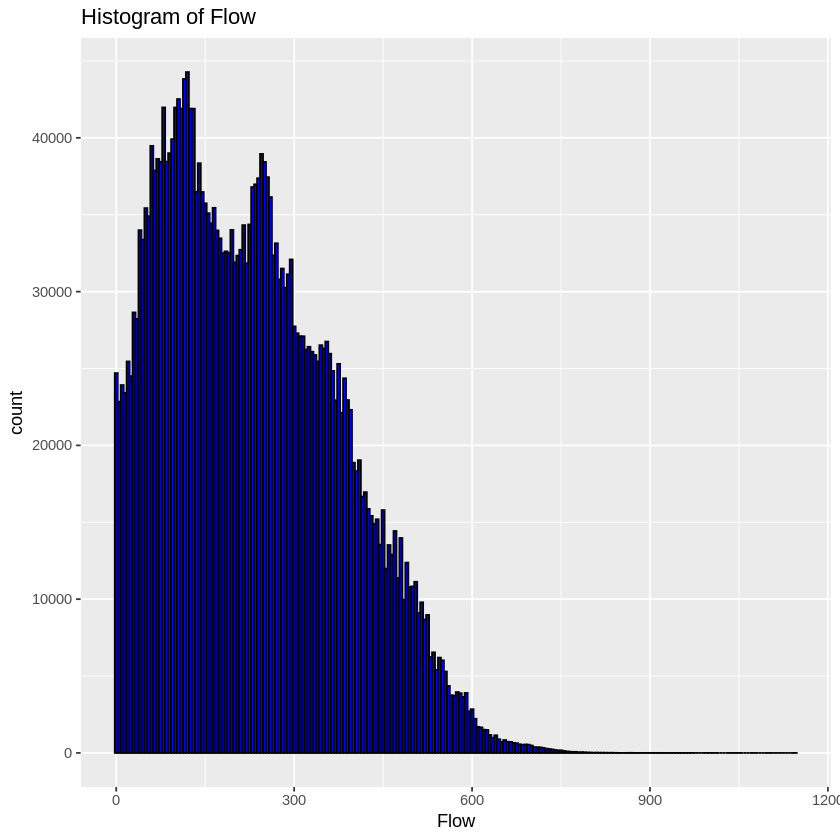

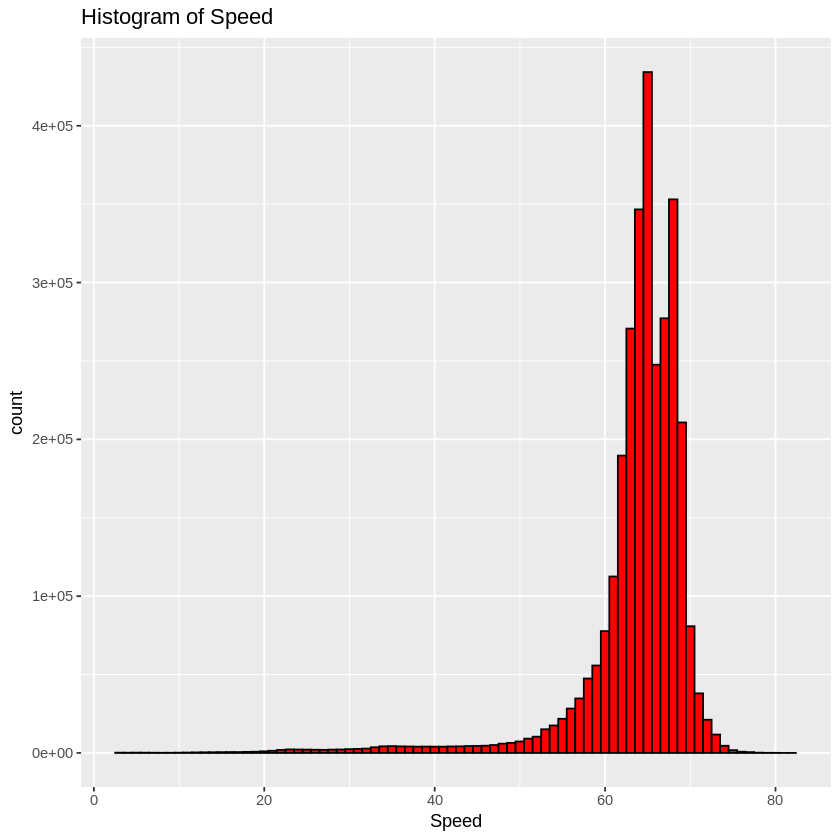

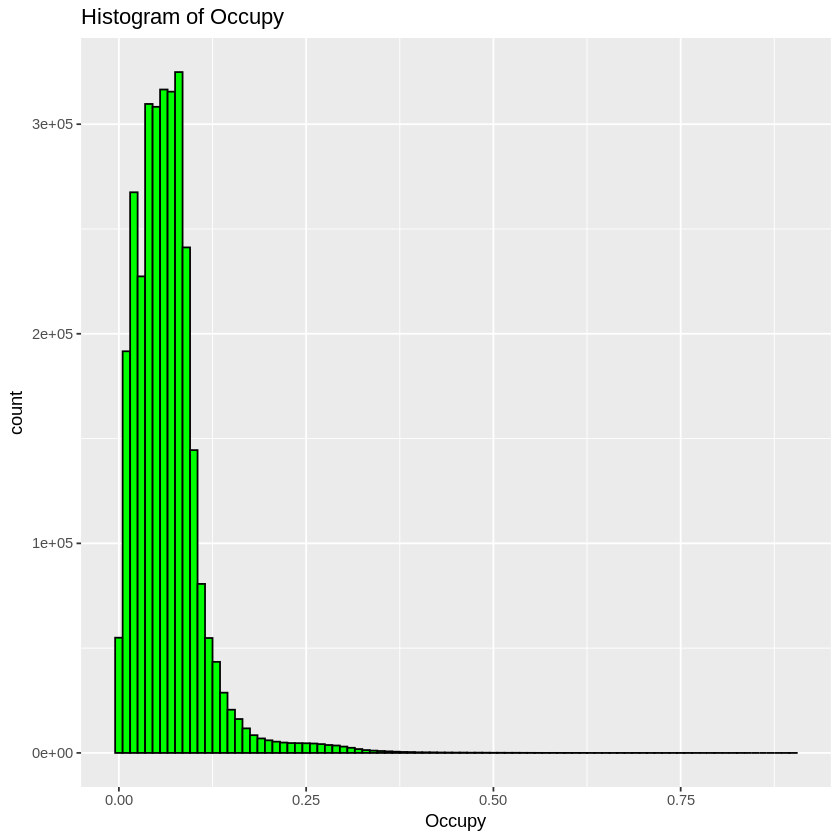

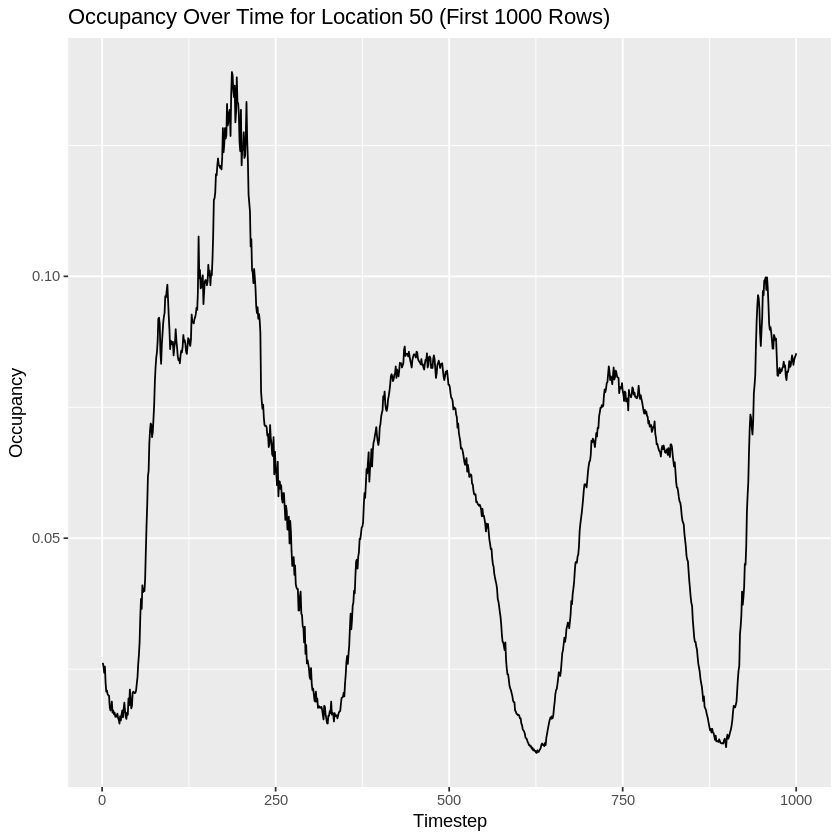

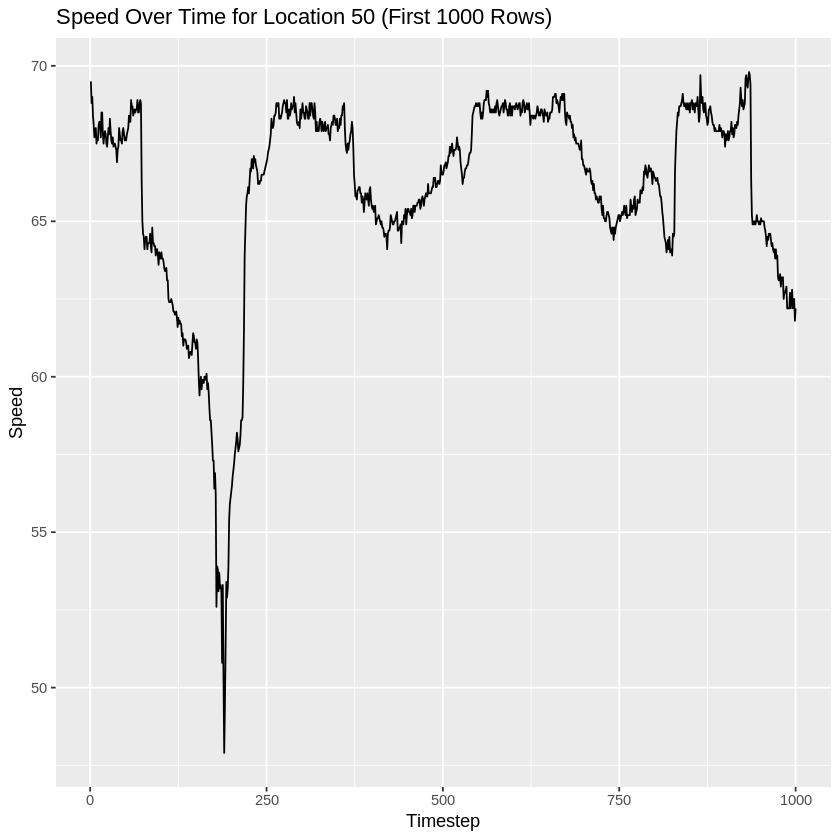

ERROR: Error in adf.test(tf_flow): could not find function "adf.test"


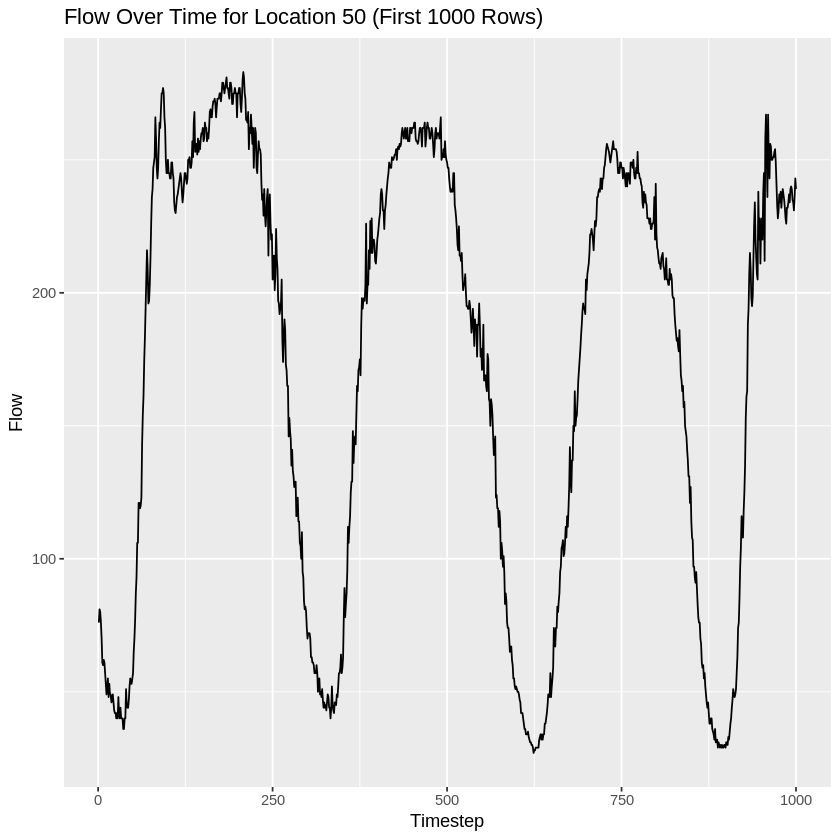

In [14]:
# Convert traffic data into time-series format
traffic_ts <- ts(traffic[, c("flow", "speed", "occupy")], start=1, frequency=1440)

# Exploratory Data Analysis - EDA & Data Visualization
ggplot(traffic, aes(x = flow)) +
  geom_histogram(fill = "blue", color = "black", binwidth = 5) +
  labs(title = "Histogram of Flow", x = "Flow")

ggplot(traffic, aes(x = speed)) +
  geom_histogram(fill = "red", color = "black", binwidth = 1) +
  labs(title = "Histogram of Speed", x = "Speed")

ggplot(traffic, aes(x = occupy)) +
  geom_histogram(fill = "green", color = "black", binwidth = 0.01) +
  labs(title = "Histogram of Occupy", x = "Occupy")

# Filter for a specific location
traffic_filtered <- subset(traffic, location == 50)
traffic_filtered_1000 <- head(traffic_filtered, 1000)

# Line plots
ggplot(traffic_filtered_1000, aes(x = timestep, y = occupy)) +
  geom_line() +
  labs(title = "Occupancy Over Time for Location 50 (First 1000 Rows)",
       x = "Timestep", y = "Occupancy")

ggplot(traffic_filtered_1000, aes(x = timestep, y = speed)) +
  geom_line() +
  labs(title = "Speed Over Time for Location 50 (First 1000 Rows)",
       x = "Timestep", y = "Speed")

ggplot(traffic_filtered_1000, aes(x = timestep, y = flow)) +
  geom_line() +
  labs(title = "Flow Over Time for Location 50 (First 1000 Rows)",
       x = "Timestep", y = "Flow")

# Convert to time series
tf_occupy <- ts(traffic_filtered_1000$occupy, start=1, frequency=1440)
tf_speed <- ts(traffic_filtered_1000$speed, start=1, frequency=1440)
tf_flow <- ts(traffic_filtered_1000$flow, start=1, frequency=1440)

# Check stationarity with Augmented Dickey-Fuller Test
traffic_adf_flow <- adf.test(tf_flow)
print(traffic_adf_flow)
traffic_diff_flow <- adf.test(diff(tf_flow))
print(traffic_diff_flow)

traffic_adf_speed <- adf.test(tf_speed)
print(traffic_adf_speed)
traffic_diff_speed <- adf.test(diff(tf_speed))
print(traffic_diff_speed)

traffic_adf_occupy <- adf.test(tf_occupy)
print(traffic_adf_occupy)
traffic_diff_occupy <- adf.test(diff(tf_occupy))
print(traffic_diff_occupy)

# ACF and PACF plots
acf(tf_flow, main="ACF plot of Flow")
pacf(tf_flow, main="PACF plot of Flow")

In [15]:
#check stationarity
tf_occupy<- traffic_filtered_1000$occupy
tf_speed<- traffic_filtered_1000$speed
tf_flow<- traffic_filtered_1000$flow

# Load the tseries package
library(tseries)  # This line is added to load the package containing adf.test

#Test with Augmented Dickey Fuller Test
traffic_adf_flow <- adf.test(tf_flow)
print(traffic_adf_flow)
diff_tf_flow<- diff(tf_flow)
traffic_diff_flow <- adf.test(diff_tf_flow)
print(traffic_diff_flow)

traffic_adf_speed <- adf.test(tf_speed)
print(traffic_adf_speed)
traffic_adf_speed <- diff(tf_speed)
traffic_diff_speed<- adf.test(traffic_adf_speed)
traffic_diff_speed

traffic_adf_occupy <- adf.test(tf_occupy)
traffic_adf_occupy
traffic_adf_occupy <- diff(tf_occupy)
traffic_diff_occupy <- adf.test(traffic_adf_occupy)
traffic_diff_occupy


	Augmented Dickey-Fuller Test

data:  tf_flow
Dickey-Fuller = -2.641, Lag order = 9, p-value = 0.307
alternative hypothesis: stationary



Warning message in adf.test(diff_tf_flow):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  diff_tf_flow
Dickey-Fuller = -5.6646, Lag order = 9, p-value = 0.01
alternative hypothesis: stationary


	Augmented Dickey-Fuller Test

data:  tf_speed
Dickey-Fuller = -2.2388, Lag order = 9, p-value = 0.4772
alternative hypothesis: stationary



Warning message in adf.test(traffic_adf_speed):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  traffic_adf_speed
Dickey-Fuller = -8.912, Lag order = 9, p-value = 0.01
alternative hypothesis: stationary



	Augmented Dickey-Fuller Test

data:  tf_occupy
Dickey-Fuller = -2.3697, Lag order = 9, p-value = 0.4218
alternative hypothesis: stationary


Warning message in adf.test(traffic_adf_occupy):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  traffic_adf_occupy
Dickey-Fuller = -5.7259, Lag order = 9, p-value = 0.01
alternative hypothesis: stationary


[1] 0.0262 0.0255 0.0243 0.0255 0.0224 0.0207 0.0209 0.0202 0.0200 0.0199
  [11] 0.0177 0.0171 0.0176 0.0188 0.0167 0.0171 0.0164 0.0167 0.0159 0.0162
  [21] 0.0159 0.0165 0.0157 0.0153 0.0146 0.0160 0.0152 0.0163 0.0171 0.0158
  [31] 0.0174 0.0186 0.0171 0.0159 0.0155 0.0167 0.0163 0.0194 0.0181 0.0211
  [41] 0.0192 0.0175 0.0180 0.0205 0.0207 0.0205 0.0204 0.0205 0.0210 0.0223
  [51] 0.0235 0.0260 0.0277 0.0301 0.0350 0.0384 0.0365 0.0410 0.0397 0.0404
  [61] 0.0399 0.0423 0.0476 0.0525 0.0564 0.0618 0.0629 0.0681 0.0705 0.0719
  [71] 0.0716 0.0693 0.0703 0.0728 0.0755 0.0799 0.0826 0.0845 0.0855 0.0876
  [81] 0.0919 0.0921 0.0909 0.0855 0.0833 0.0869 0.0890 0.0911 0.0923 0.0930
  [91] 0.0962 0.0960 0.0972 0.0984 0.0955 0.0924 0.0898 0.0861 0.0877 0.0874
 [101] 0.0870 0.0875 0.0849 0.0865 0.0874 0.0899 0.0877 0.0864 0.0847 0.0840
 [111] 0.0843 0.0834 0.0849 0.0858 0.0855 0.0865 0.0888 0.0875 0.0878 0.0871
 [121] 0.0856 0.0852 0.0866 0.0882 0.0880 0.0872 0.0867 0.0880 0.0927 0.0913
 [131] 0.0912 0.0910 0.0918 0.0922 0.0928 0.0940 0.0936 0.0970 0.1076 0.0996
 [141] 0.1012 0.0977 0.0980 0.0995 0.1002 0.0947 0.0971 0.0990 0.0993 0.0992
 [151] 0.0983 0.0991 0.1022 0.1002 0.1011 0.0983 0.1005 0.1002 0.1032 0.1078
 [161] 0.1146 0.1149 0.1160 0.1195 0.1193 0.1212 0.1225 0.1213 0.1211 0.1207
 [171] 0.1211 0.1204 0.1226 0.1283 0.1237 0.1252 0.1283 0.1263 0.1269 0.1329
 [181] 0.1288 0.1295 0.1313 0.1318 0.1268 0.1348 0.1390 0.1384 0.1355 0.1342
 [191] 0.1364 0.1294 0.1314 0.1380 0.1333 0.1330 0.1310 0.1256 0.1239 0.1318
 [201] 0.1212 0.1249 0.1241 0.1275 0.1226 0.1230 0.1270 0.1333 0.1261 0.1222
 [211] 0.1156 0.1140 0.1124 0.1057 0.1071 0.1012 0.1007 0.0987 0.1014 0.0998
 [221] 0.0977 0.0943 0.0930 0.0941 0.0919 0.0928 0.0917 0.0892 0.0780 0.0762
 [231] 0.0747 0.0755 0.0730 0.0716 0.0714 0.0715 0.0712 0.0696 0.0699 0.0674
 [241] 0.0679 0.0716 0.0691 0.0681 0.0660 0.0657 0.0693 0.0622 0.0665 0.0634
 [251] 0.0622 0.0601 0.0646 0.0580 0.0609 0.0608 0.0594 0.0601 0.0576 0.0568
 [261] 0.0586 0.0586 0.0560 0.0535 0.0562 0.0551 0.0517 0.0516 0.0541 0.0490
 [271] 0.0533 0.0513 0.0473 0.0447 0.0454 0.0464 0.0430 0.0448 0.0412 0.0406
 [281] 0.0403 0.0403 0.0362 0.0362 0.0389 0.0398 0.0356 0.0353 0.0332 0.0329
 [291] 0.0301 0.0331 0.0279 0.0296 0.0261 0.0267 0.0260 0.0251 0.0235 0.0231
 [301] 0.0252 0.0222 0.0210 0.0213 0.0203 0.0190 0.0188 0.0207 0.0188 0.0194
 [311] 0.0176 0.0179 0.0179 0.0176 0.0176 0.0178 0.0172 0.0163 0.0154 0.0180
 [321] 0.0178 0.0163 0.0156 0.0147 0.0146 0.0161 0.0161 0.0170 0.0166 0.0188
 [331] 0.0163 0.0167 0.0163 0.0150 0.0166 0.0161 0.0160 0.0162 0.0156 0.0161
 [341] 0.0167 0.0169 0.0170 0.0183 0.0195 0.0196 0.0197 0.0205 0.0198 0.0223
 [351] 0.0240 0.0264 0.0275 0.0260 0.0279 0.0295 0.0328 0.0356 0.0326 0.0344
 [361] 0.0371 0.0377 0.0400 0.0395 0.0430 0.0456 0.0459 0.0442 0.0465 0.0473
 [371] 0.0499 0.0498 0.0509 0.0521 0.0522 0.0530 0.0563 0.0586 0.0577 0.0603
 [381] 0.0632 0.0624 0.0645 0.0664 0.0608 0.0634 0.0641 0.0670 0.0637 0.0667
 [391] 0.0682 0.0687 0.0696 0.0703 0.0712 0.0696 0.0685 0.0678 0.0687 0.0712
 [401] 0.0718 0.0732 0.0739 0.0744 0.0771 0.0765 0.0780 0.0756 0.0746 0.0743
 [411] 0.0750 0.0765 0.0772 0.0781 0.0793 0.0809 0.0813 0.0809 0.0800 0.0803
 [421] 0.0812 0.0814 0.0828 0.0806 0.0822 0.0817 0.0809 0.0820 0.0835 0.0833
 [431] 0.0834 0.0826 0.0830 0.0834 0.0860 0.0866 0.0848 0.0852 0.0852 0.0852
 [441] 0.0847 0.0856 0.0847 0.0839 0.0833 0.0826 0.0840 0.0846 0.0851 0.0851
 [451] 0.0849 0.0845 0.0856 0.0855 0.0843 0.0839 0.0837 0.0835 0.0832 0.0842
 [461] 0.0831 0.0832 0.0826 0.0822 0.0833 0.0841 0.0839 0.0853 0.0826 0.0830
 [471] 0.0846 0.0847 0.0844 0.0825 0.0831 0.0825 0.0842 0.0849 0.0842 0.0824
 [481] 0.0806 0.0815 0.0831 0.0834 0.0839 0.0833 0.0825 0.0832 0.0833 0.0834
 [491] 0.0820 0.0809 0.0802 0.0809 0.0818 0.0814 0.0820 0.0807 0.0793 0.0793
 [501] 0.0788 0.0776 0.0768 0.0767 0.0762 0.0746 0.0750 0.0747 0.0748 0.0736
 [511] 0.0732 0.0711 0.0719 0.0701 0.0693 0.0685 0.0671 0.0672 0.0669 0.0663

[1] 1000

[1] 799

[1] 201

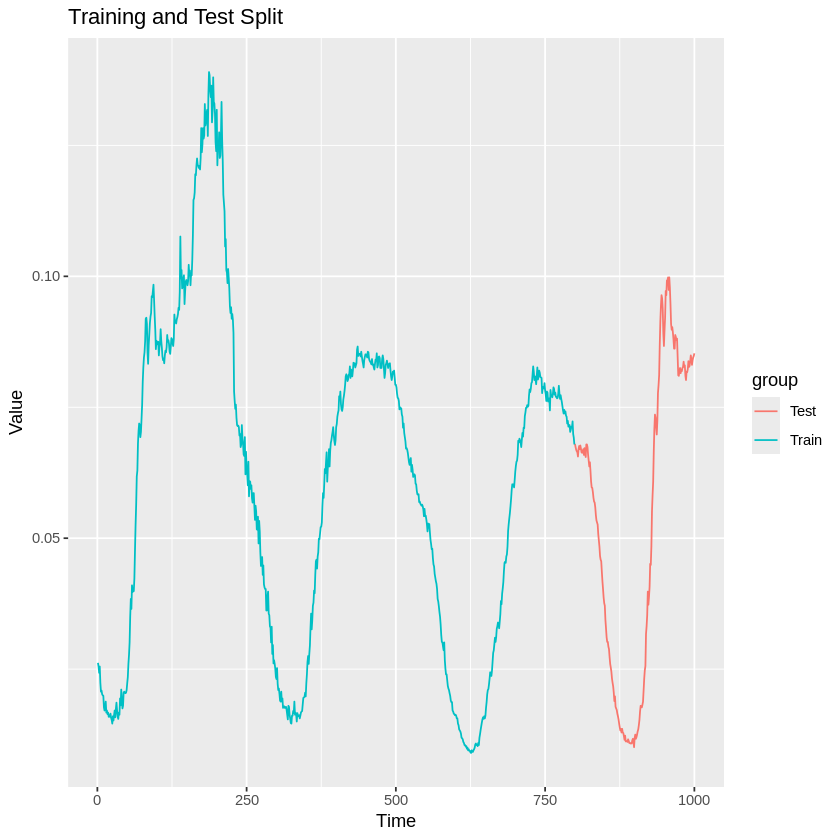

In [16]:
# filtered for 1,000 rows
tf_measure <- traffic_filtered_1000$occupy
View(tf_measure)
length(tf_measure)

tf_measure<- replace_na(tf_measure, mean(tf_measure, na.rm = TRUE))
#tf_measure
tf_measure_training <- tf_measure[1:799]
length(tf_measure_training)

# the last 200 values for testing, slicing
measure_test <- tf_measure[800:1000]
length(measure_test)
#measure_test

#Create a data frame with time series data and a group indicator
plot_data <- data.frame(
 time = 1:length(tf_measure),
  value = tf_measure,
  group = c(rep("Train", length(tf_measure_training)), rep("Test", length(measure_test)))
)

ggplot(plot_data, aes(x = time, y = value, color = group)) +
  geom_line() +
  labs(title = "Training and Test Split", x = "Time", y = "Value") +
  theme_grey()

In [17]:
# Install the reshape2 package
install.packages("reshape2")

# Load the reshape2 package
library(reshape2)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘reshape2’


The following object is masked from ‘package:tidyr’:

    smiths




Series: tf_measure_training 
ARIMA(2,1,2) with drift 

Coefficients:
         ar1      ar2      ma1     ma2  drift
      1.7712  -0.7817  -1.8705  0.9030  0e+00
s.e.  0.0433   0.0433   0.0302  0.0297  2e-04

sigma^2 = 3.555e-06:  log likelihood = 3875.82
AIC=-7739.63   AICc=-7739.53   BIC=-7711.54


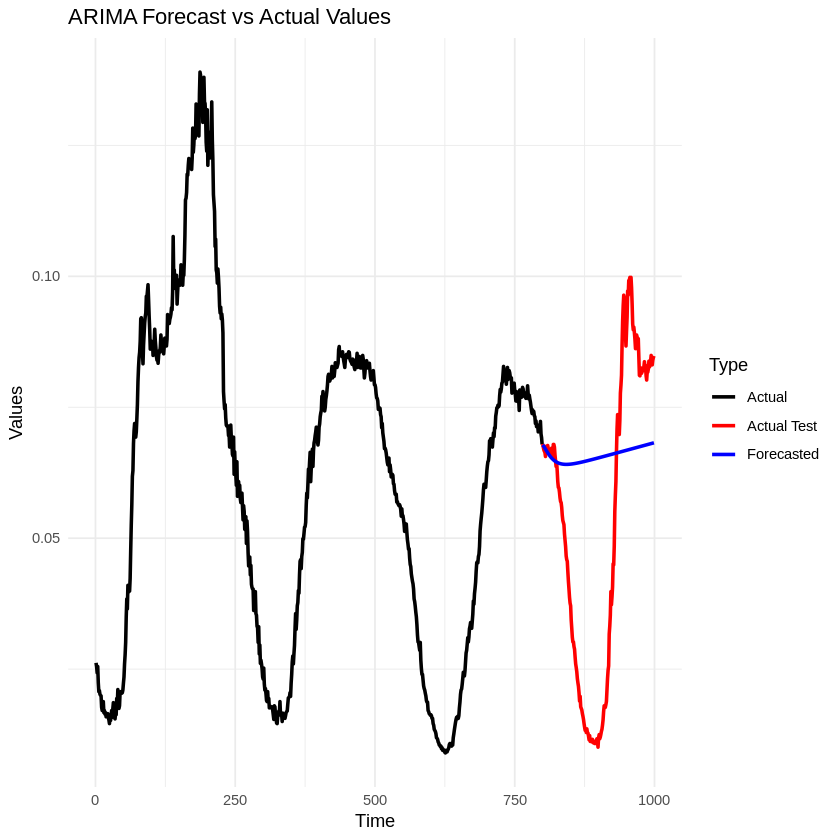


	Ljung-Box test

data:  Residuals
Q* = 7752.6, df = 10, p-value < 2.2e-16

Model df: 0.   Total lags used: 10

  Metric Training_Set      Test_Set
1     ME 7.931954e-06   -0.01298944
2   RMSE 1.878506e-03    0.03146393
3    MAE 1.246706e-03    0.02571977
4    MPE 1.530297e-01 -110.27198142
5   MAPE 2.535254e+00  124.77584400


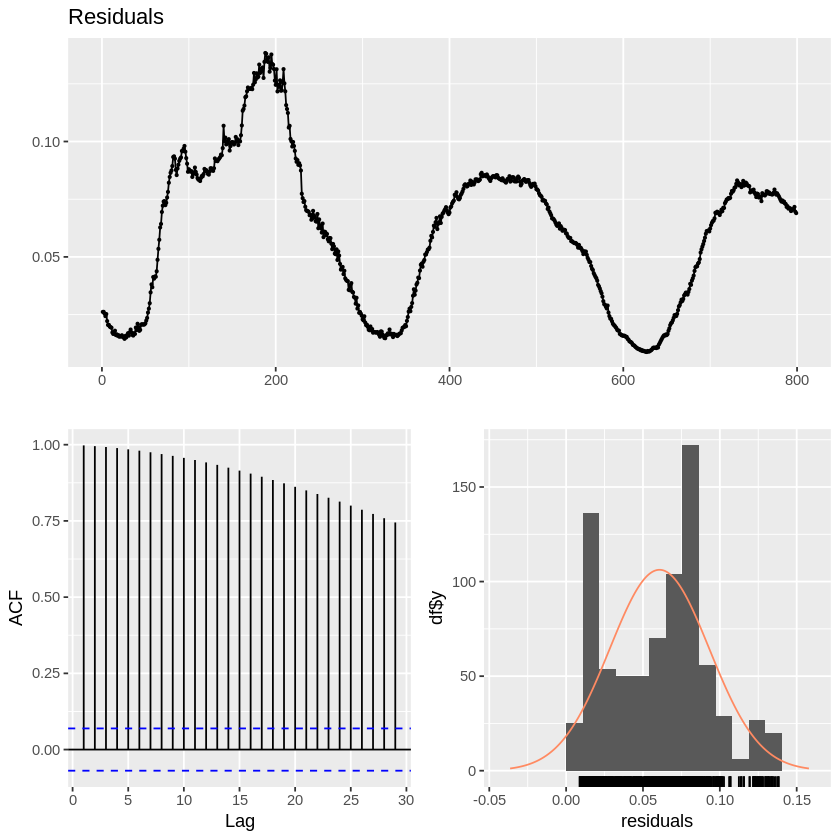

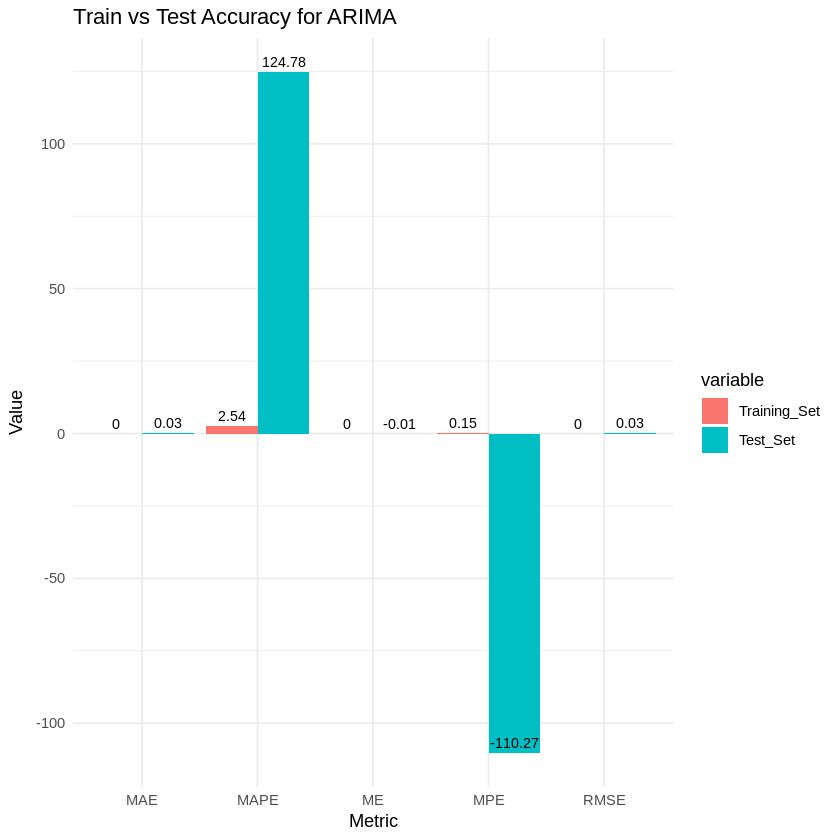

In [18]:
#1 ARIMA Model
fit_arima1 <- auto.arima(tf_measure_training)
print(fit_arima1)

forecast_arima <- forecast(fit_arima1, h = 200)

# Training Accuracy: Compare fitted values with the training set
fitted_arima <- fitted(fit_arima1)
training_accuracy_arima <- accuracy(fitted_arima, tf_measure_training)

# Combine actual and forecasted data
forecast_df <- data.frame(
  Time = 1:(length(tf_measure_training) + length(forecast_arima$mean)),
  Values = c(as.numeric(tf_measure_training), as.numeric(forecast_arima$mean)),
  Type = c(rep("Actual", length(tf_measure_training)), rep("Forecasted", length(forecast_arima$mean)))
)

# Add actual test values
forecast_df_test <- data.frame(
  Time = (length(tf_measure_training) + 1):(length(tf_measure_training) + length(measure_test[1:200])),
  Values = as.numeric(measure_test[1:200]),
  Type = "Actual Test"
)

# Combine for plotting
combined_df <- rbind(forecast_df, forecast_df_test)

# Plot the combined data
ggplot(combined_df, aes(x = Time, y = Values, color = Type)) +
  geom_line(linewidth = 1) +
  labs(
    title = "ARIMA Forecast vs Actual Values",
    x = "Time",
    y = "Values"
  ) +
  scale_color_manual(values = c("Actual" = "black", "Forecasted" = "blue", "Actual Test" = "red")) +
  theme_minimal()

# Test Accuracy: Compare forecasted values with the test set
predicted_values <- forecast_arima$mean
test_accuracy_arima <- accuracy(predicted_values, measure_test[1:200])
checkresiduals(fitted_arima)


# Combine Training and Test Accuracy into One Table
results_arima <- data.frame(
  Metric = c("ME", "RMSE", "MAE", "MPE", "MAPE"),
  Training_Set = as.numeric(training_accuracy_arima),
  Test_Set = as.numeric(test_accuracy_arima)
)

# Print Results
print(results_arima)
results_melt_arima <- reshape2::melt(results_arima, id.vars = "Metric")
ggplot(results_melt_arima, aes(x = Metric, y = value, fill = variable)) +
  geom_bar(stat = "identity", position = "dodge") +
  geom_text(aes(label = round(value, 2)),
            position = position_dodge(width = 0.9),
            vjust = -0.5, size = 3) +
  labs(title = "Train vs Test Accuracy for ARIMA", y = "Value", x = "Metric") +
  theme_minimal()


[1] 1000


	Ljung-Box test

data:  Residuals from ARIMA(3,1,3)
Q* = 24.371, df = 4, p-value = 6.731e-05

Model df: 6.   Total lags used: 10



[1] 201

[1] 0.05300199

Warning message in cor(measure_test, kal_tf):
“the standard deviation is zero”


[1] NA

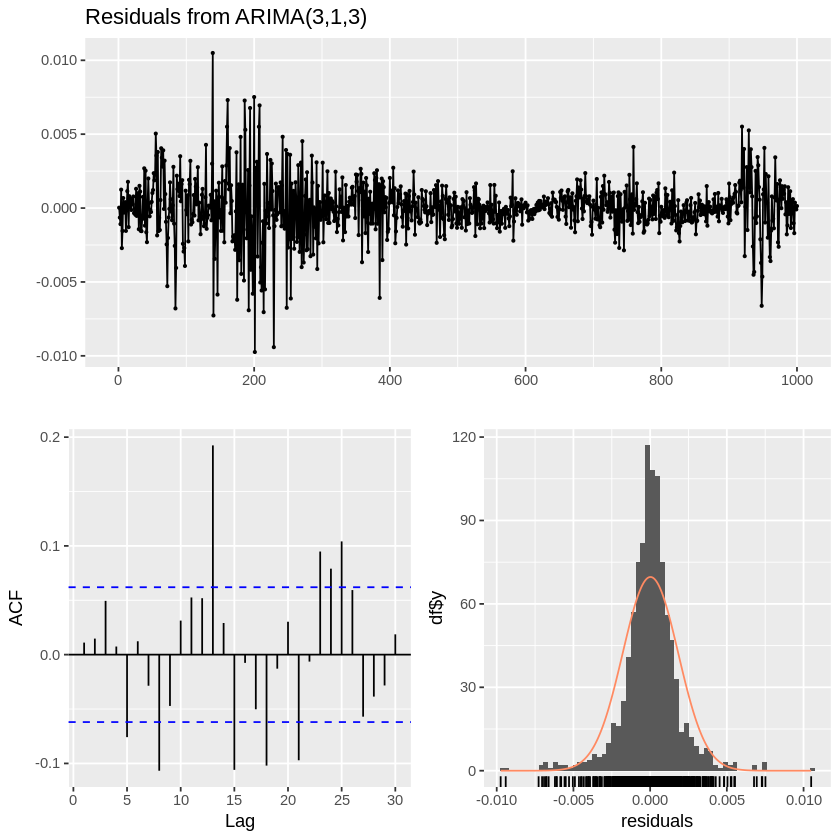

  Metric Training_Set     Test_Set
1     ME 1.886665e-05   0.05300199
2   RMSE 1.868472e-03   0.06068685
3    MAE 1.249593e-03   0.05300199
4    MPE 1.315918e-01 100.00000000
5   MAPE 2.522579e+00 100.00000000


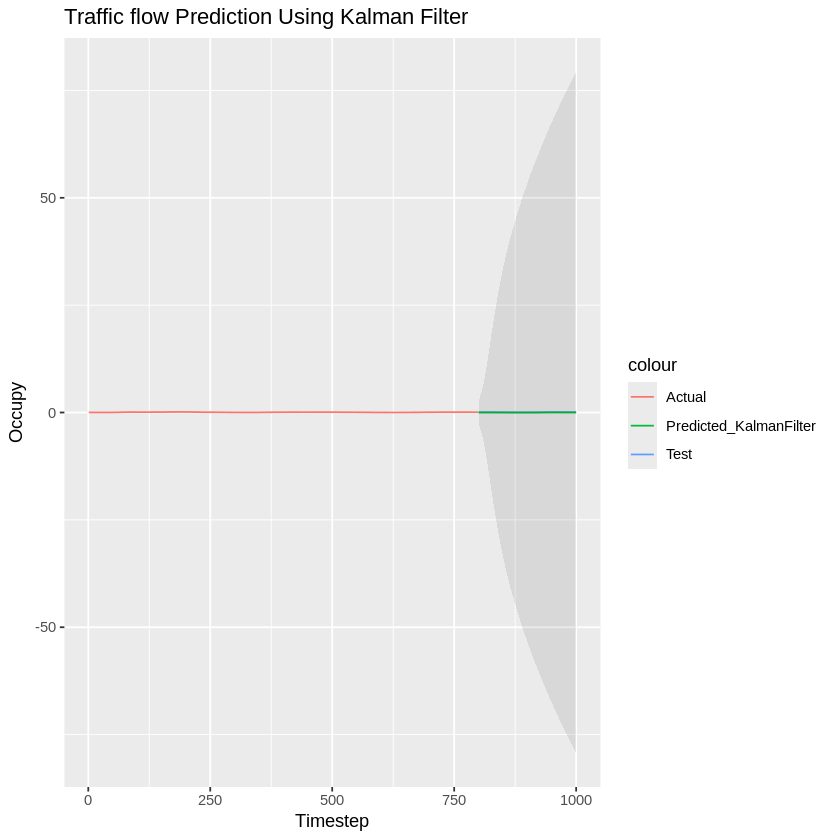

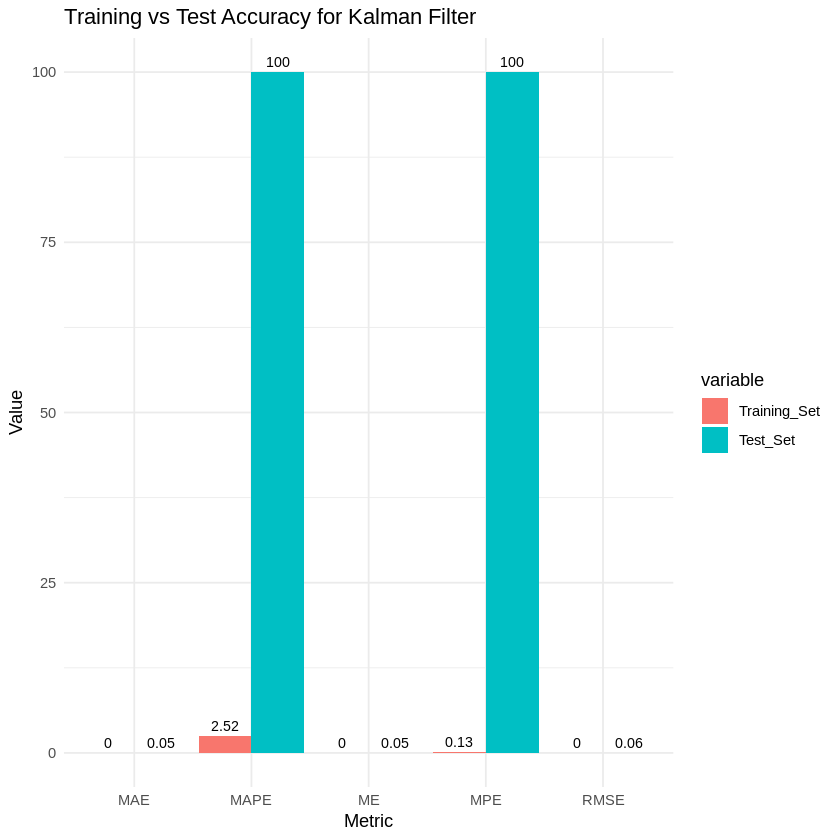

In [19]:
#2 Kalman Filter and Test
len_sum <- length(tf_measure_training) + length(measure_test)
len_sum
fit_kal1 <- auto.arima(tf_measure)
fit_kal1 <- arima(tf_measure, c(3, 1, 3))
checkresiduals(fit_kal1)

# Forecast using the Kalman filter
kal_forecast <- KalmanForecast(201, fit_kal1$model, update=TRUE)
kal_tf <- kal_forecast$pred + fit_kal1$coef[5]

# Compute error metrics
kal_tf <- pmax(kal_tf, 0)  # Ensure no negative predictions
length(kal_tf)
mean(abs(measure_test - kal_tf)) # MAE
cor(measure_test, kal_tf) # Correlation

# Confidence intervals
lower <- kal_tf - 1.96*sqrt(kal_forecast$var)
upper <- kal_tf + 1.96*sqrt(kal_forecast$var)

# Plot predictions
p <- ggplot()
p <- p + geom_line(aes(x=1:799, y=tf_measure_training, color="Actual"))
p <- p + geom_line(aes(x=800:1000, y=measure_test, color="Test"))
p <- p + geom_line(aes(x=800:1000, y=kal_tf, color="Predicted_KalmanFilter"))
p <- p + ylab("Occupy")
p <- p + xlab("Timestep")
p <- p + ggtitle("Traffic flow Prediction Using Kalman Filter")
p <- p + geom_ribbon(aes(x=c(800:1000), y = kal_tf, ymin=lower, ymax=upper), linetype=2, alpha=0.1)
p

# Accuracy metrics
fitted_Kal <- fitted(fit_kal1)
training_accuracy <- accuracy(fitted_Kal, tf_measure_training)
test_accuracy <- accuracy(kal_tf, measure_test)

# Avoid division errors
training_accuracy[is.infinite(training_accuracy)] <- NA
test_accuracy[is.infinite(test_accuracy)] <- NA

test_accuracy <- na.omit(test_accuracy)
training_accuracy <- na.omit(training_accuracy)

colnames(training_accuracy) <- c("Training_ME", "Training_RMSE", "Training_MAE", "Training_MPE", "Training_MAPE")
colnames(test_accuracy) <- c("Test_ME", "Test_RMSE", "Test_MAE", "Test_MPE", "Test_MAPE")

results_kalman <- data.frame(
  Metric = c("ME", "RMSE", "MAE", "MPE", "MAPE"),
  Training_Set = as.numeric(training_accuracy),
  Test_Set = as.numeric(test_accuracy)
)

# Print results
print(results_kalman)

# Plot results
results_melt_kalman <- reshape2::melt(results_kalman, id.vars = "Metric")
ggplot(results_melt_kalman, aes(x = Metric, y = value, fill = variable)) +
  geom_bar(stat = "identity", position = "dodge") +
  geom_text(aes(label = round(value, 2)), position = position_dodge(width = 0.9), vjust = -0.5, size = 3) +
  labs(title = "Training vs Test Accuracy for Kalman Filter", y = "Value", x = "Metric") +
  theme_minimal()


Series: tf_measure_training 
ARIMA(2,1,2) 

Coefficients:
         ar1      ar2      ma1     ma2
      1.7700  -0.7805  -1.8698  0.9022
s.e.  0.0435   0.0436   0.0306  0.0300

sigma^2 = 3.551e-06:  log likelihood = 3875.81
AIC=-7741.63   AICc=-7741.55   BIC=-7718.22
  Metric Training_Set      Test_Set
1     ME 1.741966e-05   -0.01045779
2   RMSE 1.878514e-03    0.03120250
3    MAE 1.246895e-03    0.02623355
4    MPE 1.793433e-01 -103.01906585
5   MAPE 2.536512e+00  121.11682255


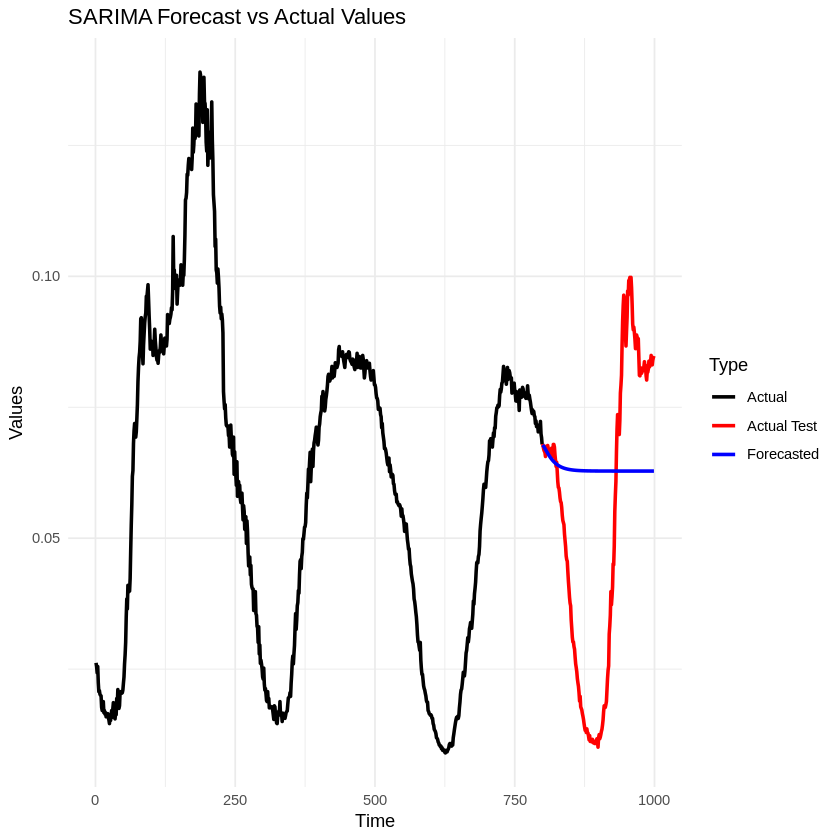

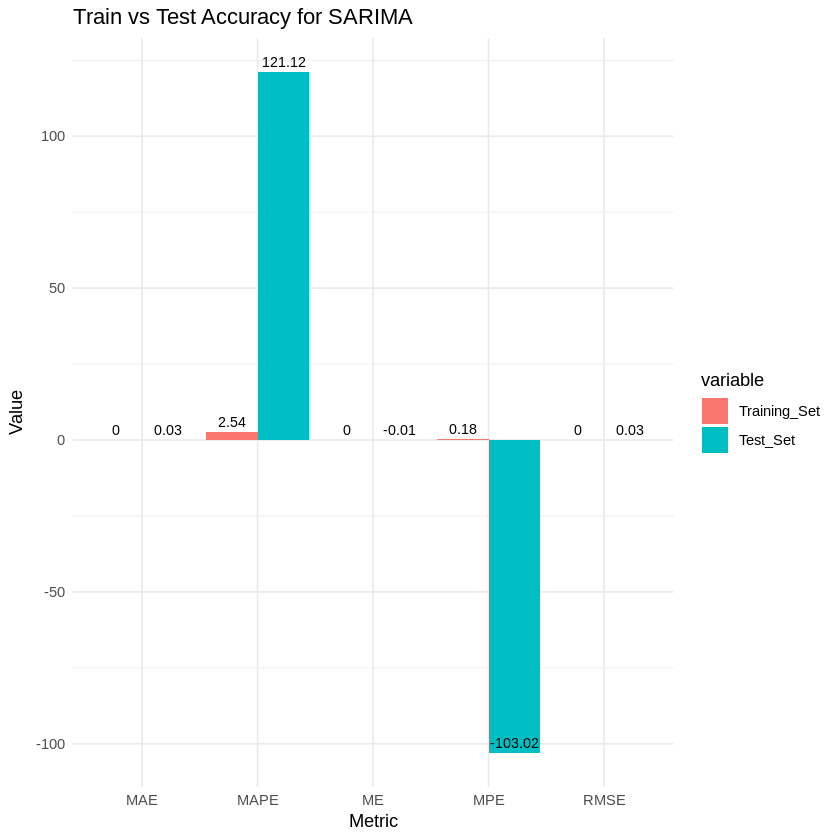

In [22]:
#3 SARIMA Model
sarima_fit <- auto.arima(
  tf_measure_training,
  seasonal = TRUE,
  stepwise = FALSE,
  approximation = FALSE
)
print(sarima_fit)

# Forecast for SARIMA
sarima_forecast <- forecast(sarima_fit, h = 200)

# Training Accuracy: Compare fitted values with the training set
fitted_sarima <- fitted(sarima_forecast)
training_accuracy_sarima <- accuracy(fitted_sarima, tf_measure_training)

# Combine actual and forecasted data
df_sarima <- data.frame(
  Time = 1:(length(tf_measure_training) + length(sarima_forecast$mean)),
  Values = c(as.numeric(tf_measure_training), as.numeric(sarima_forecast$mean)),
  Type = c(rep("Actual", length(tf_measure_training)), rep("Forecasted", length(sarima_forecast$mean)))
)

# Add actual test values
df_sarima_test <- data.frame(
  Time = (length(tf_measure_training) + 1):(length(tf_measure_training) + length(measure_test[1:200])),
  Values = as.numeric(measure_test[1:200]),
  Type = "Actual Test"
)

# Combine for plotting
df_sarima <- rbind(df_sarima, df_sarima_test)

# Plot the combined data
ggplot(df_sarima, aes(x = Time, y = Values, color = Type)) +
  geom_line(linewidth = 1) +
  labs(
    title = "SARIMA Forecast vs Actual Values",
    x = "Time",
    y = "Values"
  ) +
  scale_color_manual(values = c("Actual" = "black", "Forecasted" = "blue", "Actual Test" = "red")) +
  theme_minimal()

# Test Accuracy: Compare forecasted values with the test set
predicted_values_sarima <- sarima_forecast$mean
test_accuracy_sarima <- accuracy(predicted_values_sarima, measure_test[1:200])

# Combine Training and Test Accuracy into One Table
results_sarima <- data.frame(
  Metric = c("ME", "RMSE", "MAE", "MPE", "MAPE"),
  Training_Set = as.numeric(training_accuracy_sarima),
  Test_Set = as.numeric(test_accuracy_sarima)
)

# Print Results
print(results_sarima)
results_melt_sarima <- reshape2::melt(results_sarima, id.vars = "Metric")
ggplot(results_melt_sarima, aes(x = Metric, y = value, fill = variable)) +
  geom_bar(stat = "identity", position = "dodge") +
  geom_text(aes(label = round(value, 2)),
            position = position_dodge(width = 0.9),
            vjust = -0.5, size = 3) +
  labs(title = "Train vs Test Accuracy for SARIMA", y = "Value", x = "Metric") +
  theme_minimal()



  Metric  Training_Set      Test_Set
1     ME  -0.001803299  -0.006853127
2   RMSE   0.013284420   0.030327904
3    MAE   0.008849546   0.026342322
4    MPE -22.753140837 -92.146790964
5   MAPE  30.950982929 115.134398457


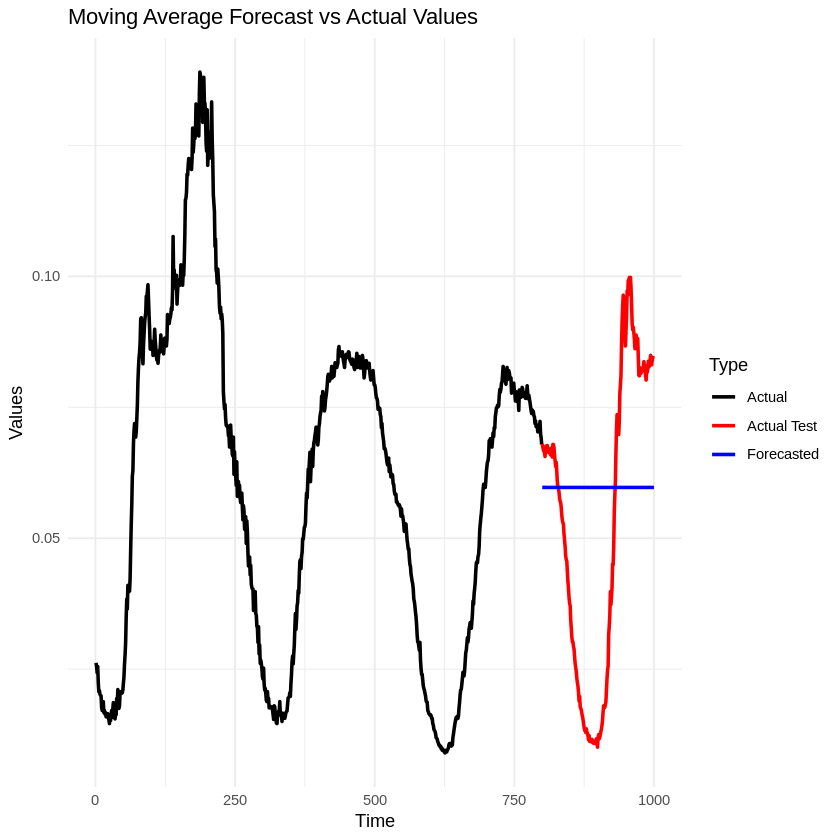

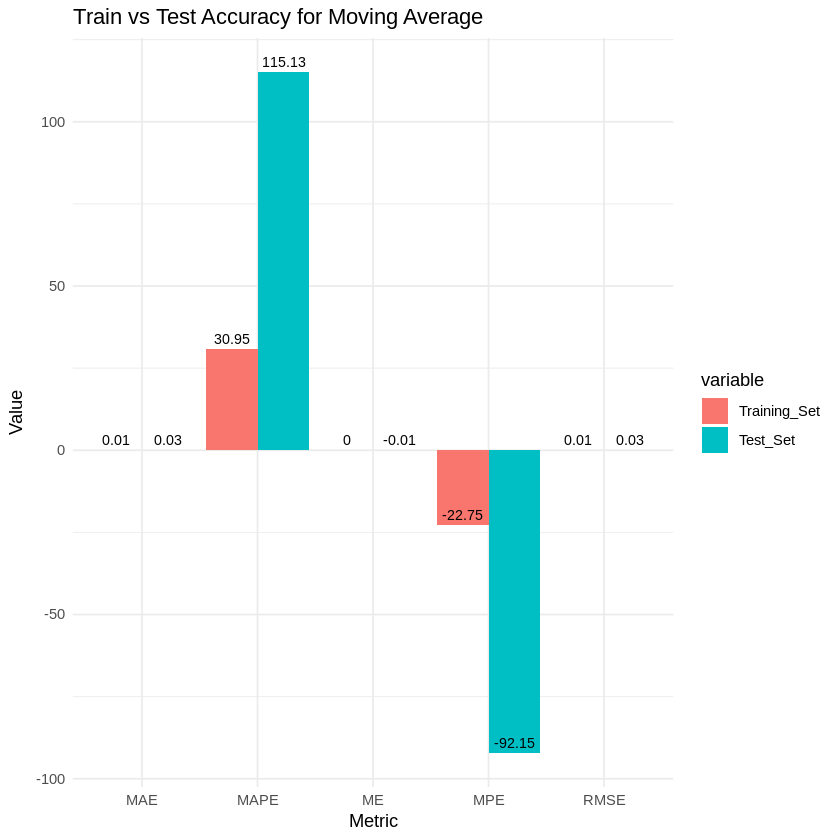

In [23]:
#4 moving average
ma_pred <- ma(tf_measure, order = 100)
#ma_pred
ma_pred <- replace_na(ma_pred, mean(ma_pred, na.rm = TRUE))
forecast_ma <- forecast(ma_pred, h = length(measure_test))

#autoplot(forecast_ma)
#checkresiduals(ma_pred)

# Training Accuracy: Compare fitted values with the training set
fitted_ma <- fitted(forecast_ma)
training_accuracy_ma <- accuracy(fitted_ma, tf_measure_training)

# Combine actual and forecasted data
df_ma <- data.frame(
  Time = 1:(length(tf_measure_training) + length(forecast_ma$mean)),
  Values = c(as.numeric(tf_measure_training), as.numeric(forecast_ma$mean)),
  Type = c(rep("Actual", length(tf_measure_training)), rep("Forecasted", length(forecast_ma$mean)))
)

# Add actual test values
df_ma_test <- data.frame(
  Time = (length(tf_measure_training) + 1):(length(tf_measure_training) + length(measure_test[1:200])),
  Values = as.numeric(measure_test[1:200]),
  Type = "Actual Test"
)

# Combine for plotting
df_ma <- rbind(df_ma, df_ma_test)

# Plot the combined data
ggplot(df_ma, aes(x = Time, y = Values, color = Type)) +
  geom_line(linewidth = 1) +
  labs(
    title = "Moving Average Forecast vs Actual Values",
    x = "Time",
    y = "Values"
  ) +
  scale_color_manual(values = c("Actual" = "black", "Forecasted" = "blue", "Actual Test" = "red")) +
  theme_minimal()

# Test Accuracy: Compare forecasted values with the test set
predicted_values_ma <- forecast_ma$mean
test_accuracy_ma <- accuracy(predicted_values_ma, measure_test[1:200])

# Combine Training and Test Accuracy into One Table
results_ma <- data.frame(
  Metric = c("ME", "RMSE", "MAE", "MPE", "MAPE"),
  Training_Set = as.numeric(training_accuracy_ma),
  Test_Set = as.numeric(test_accuracy_ma)
)

# Print Results
print(results_ma)
results_melt_ma <- reshape2::melt(results_ma, id.vars = "Metric")
ggplot(results_melt_ma, aes(x = Metric, y = value, fill = variable)) +
  geom_bar(stat = "identity", position = "dodge") +
  geom_text(aes(label = round(value, 2)),
            position = position_dodge(width = 0.9),
            vjust = -0.5, size = 3) +
  labs(title = "Train vs Test Accuracy for Moving Average", y = "Value", x = "Metric") +
  theme_minimal()



VAR Estimation Results:
Endogenous variables: tf_occupy, tf_flow 
Deterministic variables: const 
Sample size: 998 
Log Likelihood: 1657.205 
Roots of the characteristic polynomial:
0.9974 0.981 0.3114 0.09891
Call:
VAR(y = data_var, p = 2, type = "const")


Estimation results for equation tf_occupy: 
tf_occupy = tf_occupy.l1 + tf_flow.l1 + tf_occupy.l2 + tf_flow.l2 + const 

               Estimate Std. Error t value Pr(>|t|)    
tf_occupy.l1  9.899e-01  3.369e-02  29.381  < 2e-16 ***
tf_flow.l1    4.472e-05  1.030e-05   4.342 1.56e-05 ***
tf_occupy.l2  8.338e-03  3.391e-02   0.246    0.806    
tf_flow.l2   -4.493e-05  1.025e-05  -4.385 1.29e-05 ***
const         1.923e-04  1.441e-04   1.335    0.182    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


Residual standard error: 0.001947 on 993 degrees of freedom
Multiple R-Squared: 0.9963,	Adjusted R-squared: 0.9963 
F-statistic: 6.666e+04 on 4 and 993 DF,  p-value: < 2.2e-16 


Estimation results for equation tf_f

          ME RMSE MAE MPE MAPE
Test set NaN  NaN NaN NaN  NaN


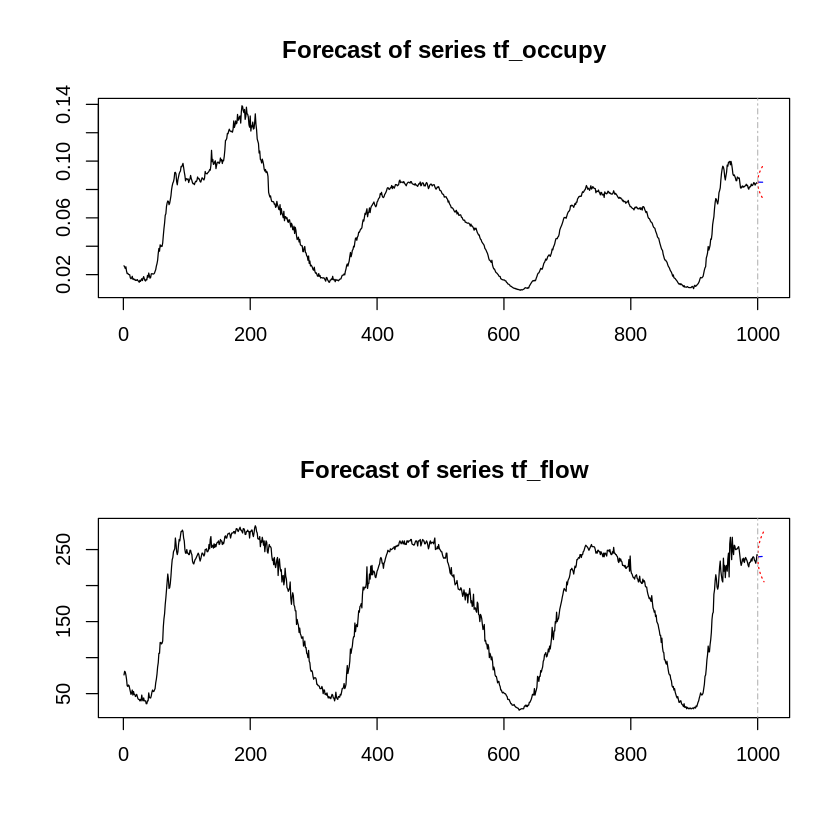

In [24]:
#4 VAR Model
library(vars)
library(forecast)

# Multivariate data
data_var <- cbind(tf_occupy, tf_flow)

# Fit VAR model
var_fit <- VAR(data_var, p = 2, type = "const")
summary(var_fit)

# Forecast for VAR
var_forecast <- predict(var_fit, n.ahead = 10)

# Extract forecasts for tf_occupy
var_forecast_occupy <- var_forecast$fcst$tf_occupy[, "fcst"]

# Create test set for tf_occupy (adjust based on your data)
test_values <- tf_occupy[(nrow(data_var) + 1):(nrow(data_var) + 10)]

# Compute accuracy metrics
var_accuracy <- accuracy(var_forecast_occupy, test_values)

plot(var_forecast)

# Custom labels for metrics
colnames(var_accuracy) <- c("ME", "RMSE", "MAE", "MPE", "MAPE")
var_accuracy_df <- as.data.frame(var_accuracy)

# Print metrics for tf_occupy
print(var_accuracy_df[, c("ME", "RMSE", "MAE", "MPE", "MAPE")])



ETS(M,Ad,N) 

Call:
ets(y = tf_measure_training)

  Smoothing parameters:
    alpha = 0.7426 
    beta  = 0.1059 
    phi   = 0.9685 

  Initial states:
    l = 0.0268 
    b = -7e-04 

  sigma:  0.0378

      AIC      AICc       BIC 
-4683.488 -4683.382 -4655.388 

Training set error measures:
                       ME        RMSE         MAE       MPE    MAPE      MASE
Training set 1.564973e-05 0.001904251 0.001269963 0.1865291 2.54771 0.9217196
                   ACF1
Training set 0.02227997

                   ME        RMSE         MAE       MPE    MAPE
Test set 1.564973e-05 0.001904251 0.001269963 0.1865291 2.54771
                   ME       RMSE        MAE       MPE     MAPE
Test set -0.004199777 0.02982996 0.02580538 -81.83487 106.9995
  Metric Training_Set      Test_Set
1     ME 1.564973e-05  -0.004199777
2   RMSE 1.904251e-03   0.029829963
3    MAE 1.269963e-03   0.025805381
4    MPE 1.865291e-01 -81.834873709
5   MAPE 2.547710e+00 106.999480326


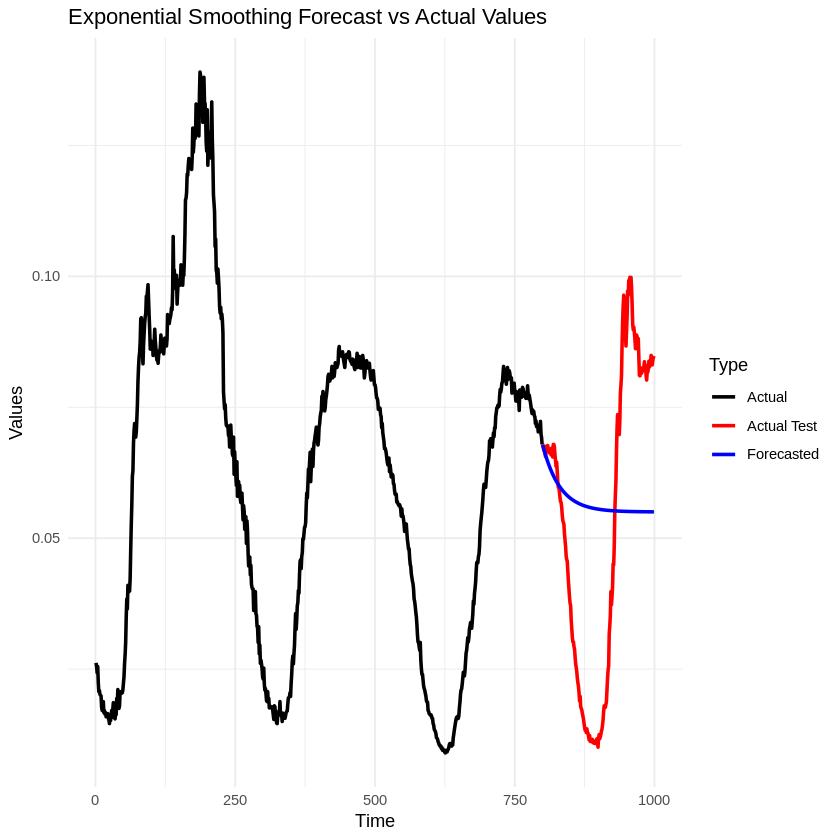

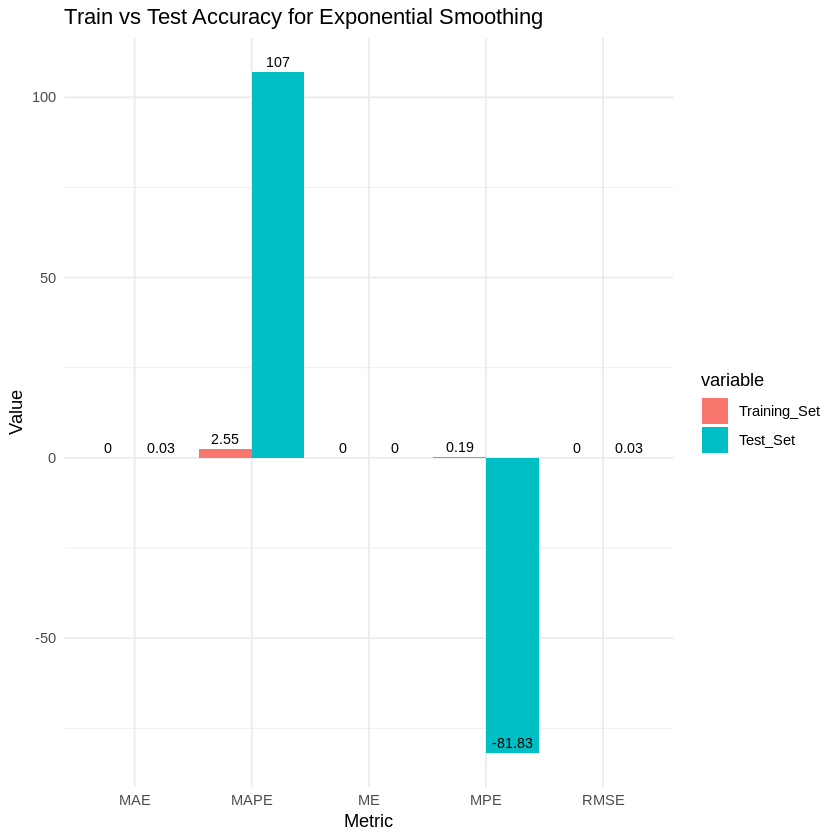

In [25]:
#5 the ETS model
ets_fit <- ets(tf_measure_training)
summary(ets_fit)

# Forecast for ETS
ets_forecast <- forecast(ets_fit, h = 200)

# Accuracy metrics
fitted_ets <- fitted(ets_forecast)
training_accuracy_ets <- accuracy(fitted_ets, tf_measure_training)
print(training_accuracy_ets)

test_accuracy_ets <- accuracy(ets_forecast$mean, measure_test[1:200])
print(test_accuracy_ets)

# Combine actual and forecasted data
df_ets <- data.frame(
  Time = 1:(length(tf_measure_training) + length(ets_forecast$mean)),
  Values = c(as.numeric(tf_measure_training), as.numeric(ets_forecast$mean)),
  Type = c(rep("Actual", length(tf_measure_training)), rep("Forecasted", length(ets_forecast$mean)))
)

# Add actual test values
df_ets_test <- data.frame(
  Time = (length(tf_measure_training) + 1):(length(tf_measure_training) + length(measure_test[1:200])),
  Values = as.numeric(measure_test[1:200]),
  Type = "Actual Test"
)

# Combine for plotting
df_ets <- rbind(df_ets, df_ets_test)

# Plot the combined data
ggplot(df_ets, aes(x = Time, y = Values, color = Type)) +
  geom_line(linewidth = 1) +
  labs(
    title = "Exponential Smoothing Forecast vs Actual Values",
    x = "Time",
    y = "Values"
  ) +
  scale_color_manual(values = c("Actual" = "black", "Forecasted" = "blue", "Actual Test" = "red")) +
  theme_minimal()

#checkresiduals(ets_fit)
#checkresiduals(ets_forecast)

# Create a data frame to store the metrics
results_ets <- data.frame(
  Metric = c("ME", "RMSE", "MAE", "MPE", "MAPE"),
  Training_Set = as.numeric(training_accuracy_ets),
  Test_Set = as.numeric(test_accuracy_ets)
)

print(results_ets)
results_melt_ets <- reshape2::melt(results_ets, id.vars = "Metric")
# Create the bar plot
ggplot(results_melt_ets, aes(x = Metric, y = value, fill = variable)) +
  geom_bar(stat = "identity", position = "dodge") +
  geom_text(aes(label = round(value, 2)),
            position = position_dodge(width = 0.9),
            vjust = -0.5, size = 3) +
  labs(title = "Train vs Test Accuracy for Exponential Smoothing", y = "Value", x = "Metric") +
  theme_minimal()


*---------------------------------*
*          GARCH Model Fit        *
*---------------------------------*

Conditional Variance Dynamics 	
-----------------------------------
GARCH Model	: sGARCH(1,1)
Mean Model	: ARFIMA(1,0,1)
Distribution	: norm 

Optimal Parameters
------------------------------------
        Estimate  Std. Error    t value Pr(>|t|)
mu      0.026167    0.001704  15.357785 0.000000
ar1     0.998468    0.001316 758.822696 0.000000
ma1     0.035126    0.033958   1.034387 0.300955
omega   0.000000    0.000001   0.026471 0.978882
alpha1  0.119344    0.030935   3.857911 0.000114
beta1   0.878637    0.027916  31.474567 0.000000

Robust Standard Errors:
        Estimate  Std. Error    t value Pr(>|t|)
mu      0.026167    0.001905  13.735006  0.00000
ar1     0.998468    0.009056 110.258477  0.00000
ma1     0.035126    0.056070   0.626468  0.53101
omega   0.000000    0.000063   0.000229  0.99982
alpha1  0.119344    2.757972   0.043272  0.96548
beta1   0.878637    2.560841 

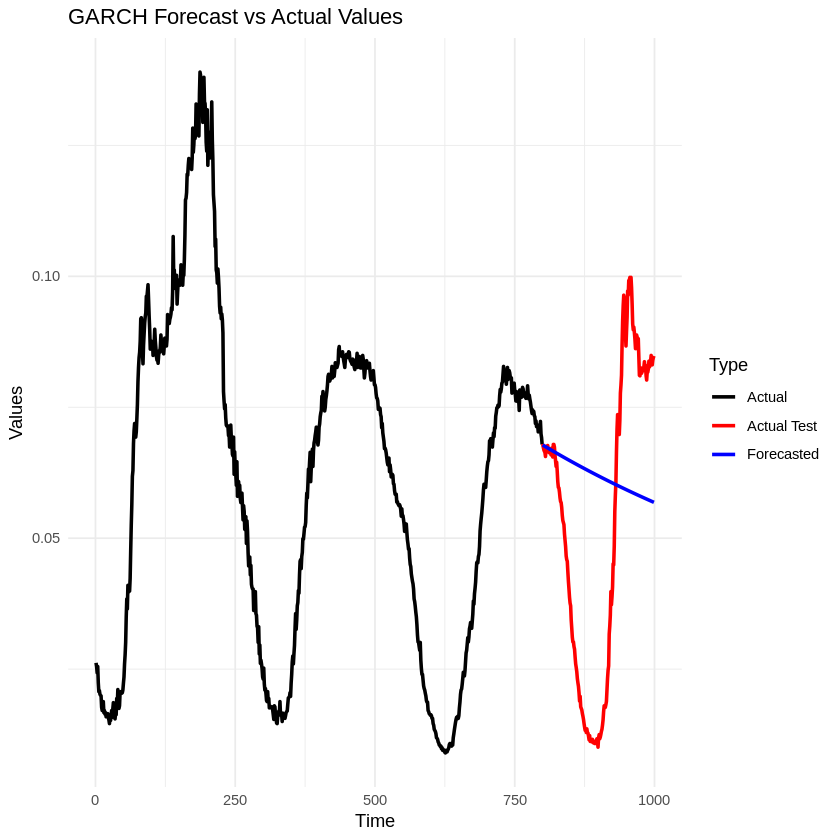

In [38]:
#6 GARCH Model

garch_spec <- ugarchspec(
  variance.model = list(model = "sGARCH", garchOrder = c(1, 1)),
  mean.model = list(armaOrder = c(1, 1), include.mean = TRUE)
)

# Fit GARCH model
garch_fit <- ugarchfit(spec = garch_spec, data = tf_measure_training)
print(garch_fit)

# Forecast for GARCH
garch_forecast <- ugarchforecast(garch_fit, n.ahead = 200)

# Extract predicted mean values
fitted_garch <- as.numeric(fitted(garch_forecast))

# Extract test data (adjust indices based on your dataset)
test_set <- as.numeric(measure_test[1:200])

# Compute accuracy metrics manually
me <- mean(fitted_garch - test_set)
rmse <- sqrt(mean((fitted_garch - test_set)^2))
mae <- mean(abs(fitted_garch - test_set))
mpe <- mean((fitted_garch - test_set) / test_set) * 100
mape <- mean(abs((fitted_garch - test_set) / test_set)) * 100

# Create a data frame to store the metrics
results_garch <- data.frame(
  Metric = c("ME", "RMSE", "MAE", "MPE", "MAPE"),
  Value = c(me, rmse, mae, mpe, mape)
)

# Print accuracy metrics
print(results_garch)

# Combine actual and forecasted data for plotting
df_garch <- data.frame(
  Time = 1:(length(tf_measure_training) + length(fitted_garch)),
  Values = c(as.numeric(tf_measure_training), fitted_garch),
  Type = c(rep("Actual", length(tf_measure_training)), rep("Forecasted", length(fitted_garch)))
)

# Add actual test values
df_garch_test <- data.frame(
  Time = (length(tf_measure_training) + 1):(length(tf_measure_training) + length(test_set)),
  Values = test_set,
  Type = "Actual Test"
)

# Combine for plotting
df_garch <- rbind(df_garch, df_garch_test)

# Plot the combined data
ggplot(df_garch, aes(x = Time, y = Values, color = Type)) +
  geom_line(linewidth = 1) +
  labs(
    title = "GARCH Forecast vs Actual Values",
    x = "Time",
    y = "Values"
  ) +
  scale_color_manual(values = c("Actual" = "black", "Forecasted" = "blue", "Actual Test" = "red")) +
  theme_minimal()


,timestep,location,flow,occupy,speed
,<int>,<int>,<dbl>,<dbl>,<dbl>
51,1,50,76,0.0262,69.5
221,2,50,81,0.0255,68.8
391,3,50,80,0.0243,69.0
561,4,50,76,0.0255,68.4
731,5,50,70,0.0224,68.1
901,6,50,61,0.0207,67.7


[1] "data.frame"

       ds                               y          
 Min.   :2016-07-01 00:00:00.00   Min.   :0.00900  
 1st Qu.:2016-07-01 00:04:09.75   1st Qu.:0.02662  
 Median :2016-07-01 00:08:19.50   Median :0.06565  
 Mean   :2016-07-01 00:08:19.50   Mean   :0.05920  
 3rd Qu.:2016-07-01 00:12:29.25   3rd Qu.:0.08263  
 Max.   :2016-07-01 00:16:39.00   Max.   :0.13900  

Disabling yearly seasonality. Run prophet with yearly.seasonality=TRUE to override this.

Disabling weekly seasonality. Run prophet with weekly.seasonality=TRUE to override this.

Disabling daily seasonality. Run prophet with daily.seasonality=TRUE to override this.



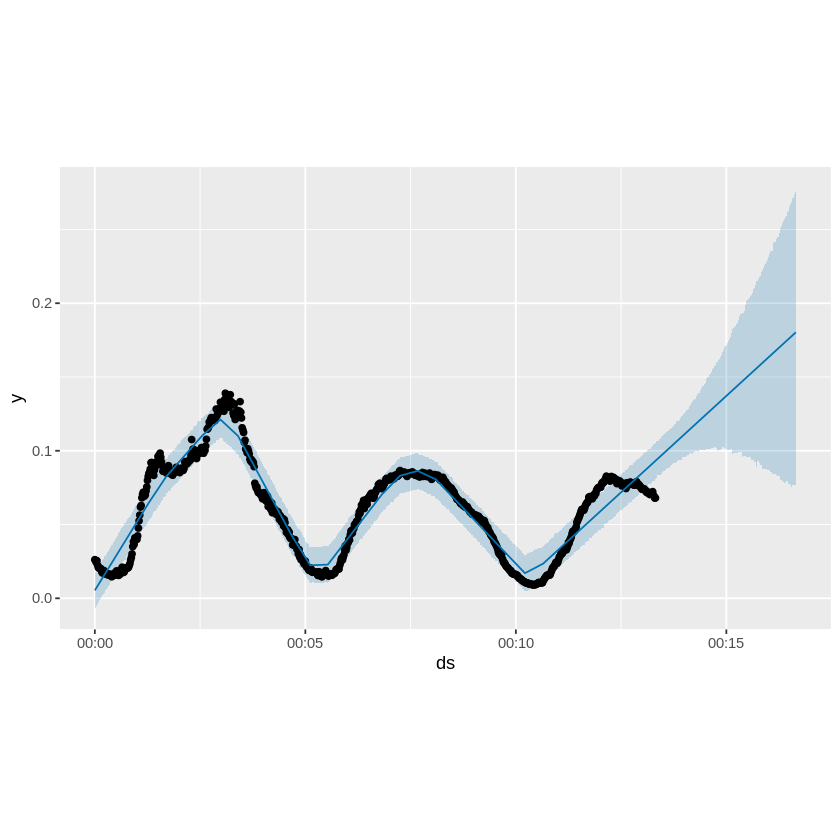

[1] "Training Set Accuracy:"
                  ME        RMSE         MAE       MPE     MAPE
Test set 4.13418e-06 0.009426548 0.007628421 -10.53106 21.27921
[1] "Testing Set Accuracy:"
                  ME       RMSE        MAE       MPE     MAPE
Test set -0.08403692 0.08893852 0.08403692 -327.1412 327.1412
  Metric  Training_Set      Test_Set
1     ME  4.134180e-06   -0.08403692
2   RMSE  9.426548e-03    0.08893852
3    MAE  7.628421e-03    0.08403692
4    MPE -1.053106e+01 -327.14124191
5   MAPE  2.127921e+01  327.14124191


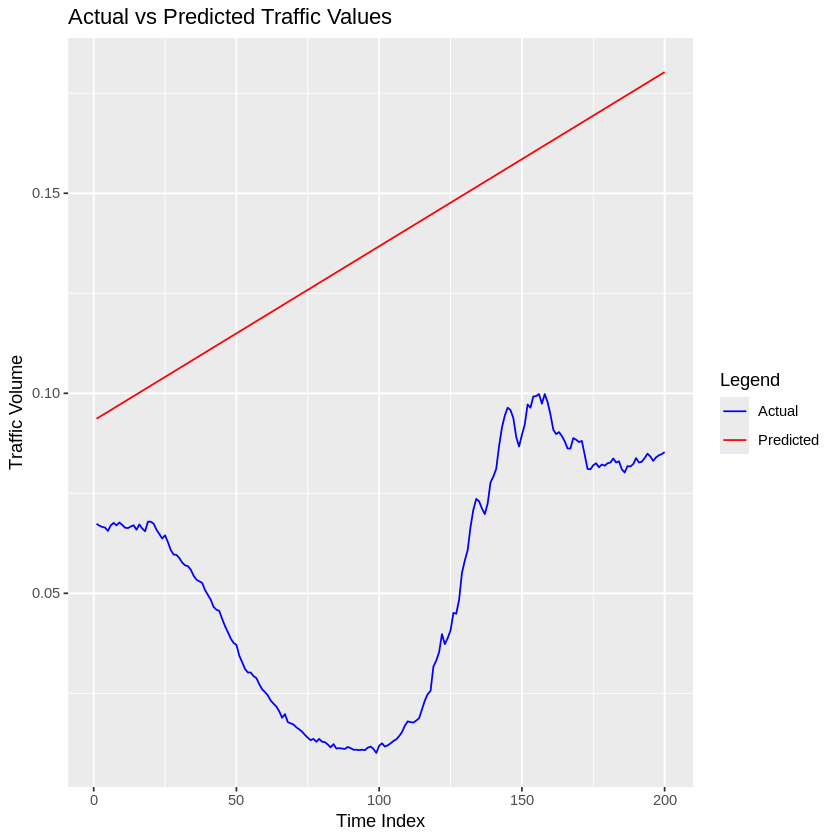

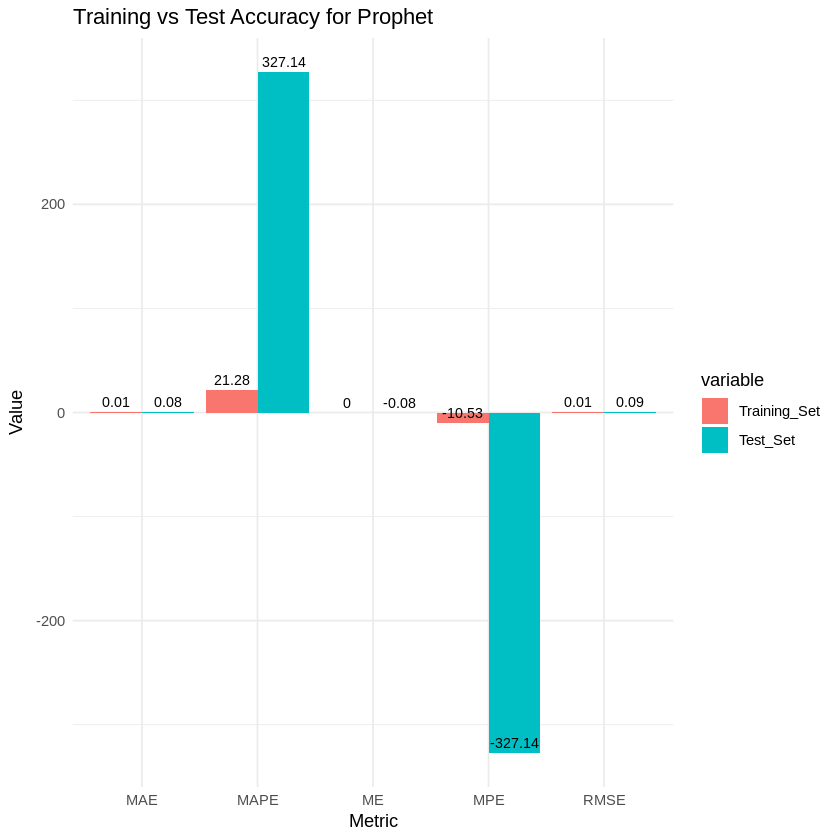

In [26]:
#9 Facebook Prophet
library(dplyr)
library(prophet)
library(ggplot2)
library(forecast)
library(reshape2)

# Check the structure of the original data
head(traffic_filtered_1000)
class(traffic_filtered_1000)
traffic_ph <- traffic_filtered_1000

# Add a datetime column starting from a specific point
start_datetime <- as.POSIXct("2016-07-01 00:00:00", tz = "UTC")
traffic_ph$datetime <- start_datetime + seconds(traffic_ph$timestep - 1)

# Select and rename columns
traffic_ph <- traffic_ph %>%
  dplyr::select(datetime, occupy) %>%
  dplyr::rename(ds = datetime, y = occupy)

# Verify the structure and range of the data
summary(traffic_ph)
if (all(traffic_ph$y == traffic_ph$y[1])) {
  stop("The target variable 'y' is constant; model fitting will fail.")
}

# Split data into training and testing sets (80-20 split)
split_index <- floor(0.8 * nrow(traffic_ph))
train_data <- traffic_ph[1:split_index, ]
test_data <- traffic_ph[(split_index + 1):nrow(traffic_ph), ]

# Create and fit the Prophet model
m <- prophet(train_data)

# Create a future dataframe
future <- make_future_dataframe(m, periods = nrow(test_data), freq = "sec")
forecast <- predict(m, future)

# Plot the forecast
plot(m, forecast)

# Align predictions with test set
test_predictions <- forecast[(nrow(train_data) + 1):nrow(forecast), ]
test_data$yhat <- test_predictions$yhat

# Compare actual vs. predicted values
comparison <- data.frame(
  TimeIndex = 1:nrow(test_data),
  Actual = test_data$y,
  Predicted = test_data$yhat
)

# Plot actual vs. predicted values
ggplot(comparison, aes(x = TimeIndex)) +
  geom_line(aes(y = Actual, color = "Actual")) +
  geom_line(aes(y = Predicted, color = "Predicted")) +
  labs(title = "Actual vs Predicted Traffic Values",
       x = "Time Index",
       y = "Traffic Volume") +
  scale_color_manual(name = "Legend", values = c("Actual" = "blue", "Predicted" = "red"))

# Accuracy for Train and Test Datasets
train_fitted_ph <- forecast[1:nrow(train_data), ]$yhat
train_accuracy_ph <- accuracy(train_fitted_ph, train_data$y)
print("Training Set Accuracy:")
print(train_accuracy_ph)

test_accuracy_ph <- accuracy(test_data$yhat, test_data$y)
print("Testing Set Accuracy:")
print(test_accuracy_ph)

# Combine Training and Test Accuracy into One Table
results_ph <- data.frame(
  Metric = c("ME", "RMSE", "MAE", "MPE", "MAPE"),
  Training_Set = as.numeric(train_accuracy_ph),
  Test_Set = as.numeric(test_accuracy_ph)
)

# Print Results
print(results_ph)
results_melt_ph <- reshape2::melt(results_ph, id.vars = "Metric")
ggplot(results_melt_ph, aes(x = Metric, y = value, fill = variable)) +
  geom_bar(stat = "identity", position = "dodge") +
  geom_text(aes(label = round(value, 2)),
            position = position_dodge(width = 0.9),
            vjust = -0.5, size = 3) +
  labs(title = "Training vs Test Accuracy for Prophet", y = "Value", x = "Metric") +
  theme_minimal()


                    flow     occupy      speed flow_future occupy_future
flow           1.0000000  0.6740394 -0.2963315   0.5352349     0.4501918
occupy         0.6740394  1.0000000 -0.7520399   0.4452821     0.4773794
speed         -0.2963315 -0.7520399  1.0000000  -0.2282664    -0.2751796
flow_future    0.5352349  0.4452821 -0.2282664   1.0000000     0.6740397
occupy_future  0.4501918  0.4773794 -0.2751796   0.6740397     1.0000000
speed_future  -0.2350300 -0.3038583  0.2335371  -0.2963315    -0.7520398
              speed_future
flow            -0.2350300
occupy          -0.3038583
speed            0.2335371
flow_future     -0.2963315
occupy_future   -0.7520398
speed_future     1.0000000


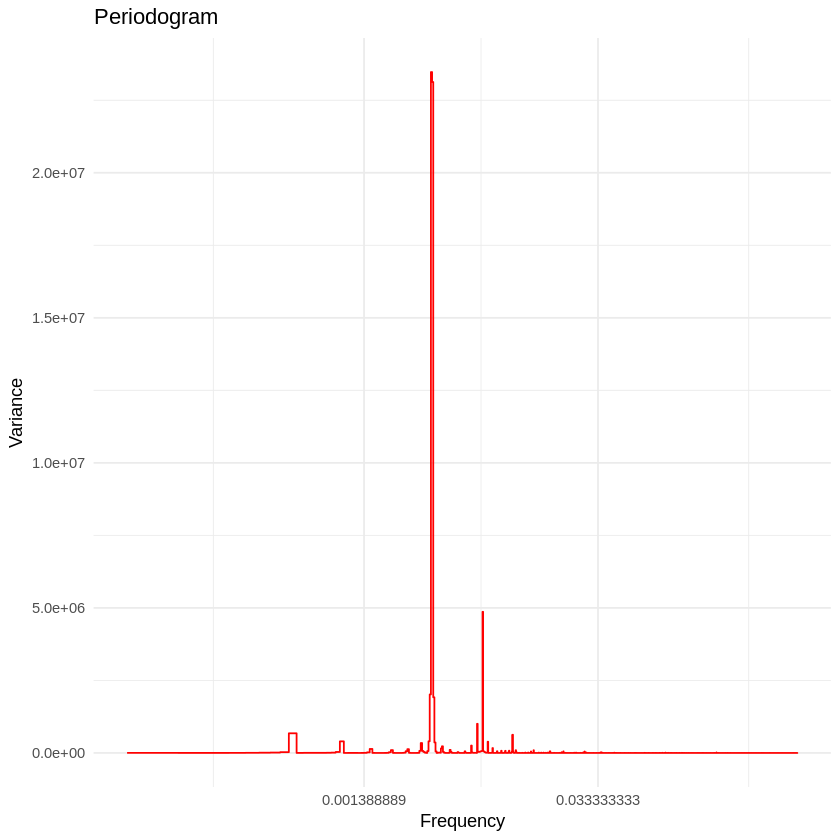

In [27]:
# Load necessary libraries
library(dplyr)
library(ggplot2)
library(stats)

# Define the correlationlag step
COR_STEP <- 1

# Create the present and future data frames
pres <- traffic %>%
  dplyr::select(flow, occupy, speed) %>%
  slice(1:(n() - COR_STEP))

future <- traffic %>%
  dplyr::select(flow, occupy, speed) %>%
  slice((COR_STEP + 1):n()) %>%
  rename_with(~ paste0(.x, "_future"))

# Join the present and future data frames
val <- bind_cols(pres, future)

# Calculate correlation
correlation_matrix <- cor(val, use = "complete.obs")

# Print the correlation matrix
print(correlation_matrix)

# Function to plot periodogram
plot_periodogram <- function(ts, detrend = "linear") {
  # Detrend the time series if necessary
  if (detrend == "linear") {
    ts <- residuals(lm(ts ~ seq_along(ts)))
  }

  # Calculate the periodogram
  spec <- spec.pgram(ts, plot = FALSE)

  # Extract frequencies and spectrum
  frequencies <- spec$freq
  spectrum <- spec$spec

  # Create a data frame for plotting
  periodogram_df <- data.frame(
    frequencies = frequencies,
    spectrum = spectrum
  )

  # Plot the periodogram
  p <- ggplot(periodogram_df, aes(x = frequencies, y = spectrum)) +
    geom_step(color = "red") +
    scale_x_log10(breaks = c(1/(30*24*60), 1/(30*24), 1/30)) +
    scale_y_continuous(labels = scales::scientific) +
    labs(
      title = "Periodogram",
      x = "Frequency",
      y = "Variance"
    ) +
    theme_minimal()

  print(p)
}

# Plot Periodgram
plot_periodogram(traffic_filtered$flow)


LSTM

In [28]:
#create dataset
create_dataset <- function(location, WINDOW_SIZE) {

  # Mask a certain location
  location_current <- traffic[traffic$location == location, ]

  # Group to hour and average 12 (5-minute) timesteps
  location_current$hour <- (location_current$timestep - 1) %/% 12
  grouped <- aggregate(. ~ hour, data = location_current, FUN = mean)

  # Add hour features
  grouped$day <- (grouped$hour %/% 24) %% 7
  grouped$hour <- grouped$hour %% 24

  one_hot_hour <- model.matrix(~ hour - 1, data = grouped)
  colnames(one_hot_hour) <- paste0("hour_", colnames(one_hot_hour))

  # Merge all the features together to get a total of 27 features
  hour_grouped <- cbind(grouped[, c("occupy", "flow", "speed")], one_hot_hour)

  X <- list()
  Y <- c()

  for (i in 1:(nrow(hour_grouped) - WINDOW_SIZE)) {
    X[[i]] <- hour_grouped[i:(i + WINDOW_SIZE - 1), ][(WINDOW_SIZE):1, ] # reverse the order
    Y[i] <- hour_grouped[i + WINDOW_SIZE, "occupy"] # index 'occupy'
  }

  return(list(X = do.call(abind::abind, c(X, along = 3)), Y = unlist(Y))) # returns (timestep, timeframe, features) and (target)
}

# Create 4D dimension for the locations
create_4d_dataset <- function(locations, WINDOW_SIZE, traffic) {
  X_list <- list()
  Y_list <- list()
  for (location in locations) {
    result <- create_dataset(location, WINDOW_SIZE)
    X_list <- append(X_list, list(result$X))
    Y_list <- append(Y_list, list(result$Y))
  }
  X <- abind::abind(X_list, along = 4)  # Create 4D array (timestep, timeframe, features, locations)
  Y <- abind::abind(Y_list, along = 2)  # Create 2D array (timestep, locations)

  return(list(X = X, Y = Y))
}

locations <- 0:169
WINDOW_SIZE <- 24
result <- create_4d_dataset(locations, WINDOW_SIZE, traffic)
X <- result$X
Y <- result$Y

cat("Shape of X: ", dim(X), "\n")
cat("Shape of Y: ", dim(Y), "\n")

# Define train and test sizes
TRAIN_SIZE <- 0.8
TEST_SIZE  <- 0.2

# Total number of timesteps
total_timesteps <- dim(X)[3]

# Calculate train and test sizes
train_size <- floor(total_timesteps * TRAIN_SIZE)
test_size  <- total_timesteps - train_size

# Split the data into train and test sets
train_X <- X[, , 1:train_size, ]
train_Y <- Y[1:train_size, ]
#View(train_X)
test_X  <- X[, , (train_size + 1):total_timesteps, ]
#View(test_X)
test_Y  <- Y[(train_size + 1):total_timesteps, ]

class(train_X)
# Print dimensions of train and test sets
cat("Shape of train_X: ", dim(train_X), "\n")
cat("Shape of train_Y: ", dim(train_Y), "\n")
cat("Shape of test_X: ", dim(test_X), "\n")
cat("Shape of test_Y: ", dim(test_Y), "\n")

# Manual Min-Max Scaling Function
min_max_scale <- function(x) {
  return((x - min(x)) / (max(x) - min(x)))
}

# Function to apply scaling to each column of a data frame or matrix
apply_scaling <- function(df) {
  return(as.data.frame(lapply(df, min_max_scale)))
}

# Reshape train_X and test_X to 2D for scaling
train_X_2d <- matrix(as.numeric(train_X), ncol = dim(train_X)[3])
test_X_2d <- matrix(as.numeric(test_X), ncol = dim(test_X)[3])

# Convert to data frames for scaling
train_X_2d_df <- as.data.frame(train_X_2d)
test_X_2d_df <- as.data.frame(test_X_2d)

# Manually scale the data
train_X_scaled_df <- apply_scaling(train_X_2d_df)
test_X_scaled_df <- apply_scaling(test_X_2d_df)

# Reshape back to original dimensions (1171, 24, 4590), (293, 24, 4590)
train_X <- array(as.numeric(unlist(train_X_scaled_df)), dim = c(dim(train_X)[1], dim(train_X)[2], ncol(train_X_scaled_df)))
test_X <- array(as.numeric(unlist(test_X_scaled_df)), dim = c(dim(test_X)[1], dim(test_X)[2], ncol(test_X_scaled_df)))

# Scale train_Y and test_Y
train_Y_scaled_df <- apply_scaling(as.data.frame(train_Y))
test_Y_scaled_df <- apply_scaling(as.data.frame(test_Y))

# Convert scaled train_Y and test_Y back to matrices
train_Y <- matrix(as.numeric(unlist(train_Y_scaled_df)), nrow = dim(train_Y)[1], ncol = dim(train_Y)[2])
test_Y <- matrix(as.numeric(unlist(test_Y_scaled_df)), nrow = dim(test_Y)[1], ncol = dim(test_Y)[2])

# Print shapes to confirm
cat("Shape of train_X: ", dim(train_X), "\n")
cat("Shape of test_X: ", dim(test_X), "\n")
cat("Shape of train_Y: ", dim(train_Y), "\n")
cat("Shape of test_Y: ", dim(test_Y), "\n")

summary(traffic)

Shape of X:  24 4 1464 170 
Shape of Y:  1464 170 


[1] "array"

Shape of train_X:  24 4 1171 170 
Shape of train_Y:  1171 170 
Shape of test_X:  24 4 293 170 
Shape of test_Y:  293 170 
Shape of train_X:  24 4 1171 
Shape of test_X:  24 4 293 
Shape of train_Y:  1171 170 
Shape of test_Y:  293 170 


    timestep        location          flow            occupy       
 Min.   :    1   Min.   :  0.0   Min.   :   0.0   Min.   :0.00000  
 1st Qu.: 4465   1st Qu.: 42.0   1st Qu.: 110.0   1st Qu.:0.03570  
 Median : 8928   Median : 84.5   Median : 215.0   Median :0.06010  
 Mean   : 8928   Mean   : 84.5   Mean   : 230.7   Mean   :0.06507  
 3rd Qu.:13392   3rd Qu.:127.0   3rd Qu.: 334.0   3rd Qu.:0.08390  
 Max.   :17856   Max.   :169.0   Max.   :1147.0   Max.   :0.89550  
     speed      
 Min.   : 3.00  
 1st Qu.:62.60  
 Median :64.90  
 Mean   :63.76  
 3rd Qu.:67.40  
 Max.   :82.30  

In [44]:
system("sudo apt install python3.10-venv python3.10-pip python3.10-dev")

In [45]:
library(reticulate)
use_python("/usr/bin/python3", required = TRUE)


In [46]:
# =====================================================
# ✅ Load Libraries
# =====================================================
library(keras)
library(tensorflow)
library(reticulate)
library(magrittr)

# =====================================================
# ✅ Use Google Colab Python path
# =====================================================
use_python("/usr/bin/python3", required = TRUE)

# Optional: See Python config
py_config()

# =====================================================
# ✅ Reinstall matching TensorFlow version from R side
# =====================================================
# This ensures compatibility between R keras and Python TensorFlow
install_keras(method = "virtualenv")  # will set up proper version

# =====================================================
# ✅ Build and compile LSTM Model
# Suppose input shape is (timesteps = 24, features = 27)
# =====================================================
timesteps <- 24
features <- 27

model <- keras_model_sequential() %>%
  layer_lstm(units = 256, return_sequences = TRUE, input_shape = c(timesteps, features)) %>%
  layer_time_distributed(layer_dense(units = 1, activation = "sigmoid")) %>%
  compile(
    loss = "mse",
    optimizer = "adam",
    metrics = "mae"
  )

# =====================================================
# ✅ Model summary
# =====================================================
summary(model)




python:         /usr/bin/python3
libpython:      /usr/lib/python3.11/config-3.11-x86_64-linux-gnu/libpython3.11.so
pythonhome:     //usr://usr
version:        3.11.11 (main, Dec  4 2024, 08:55:07) [GCC 11.4.0]
numpy:          /usr/local/lib/python3.11/dist-packages/numpy
numpy_version:  2.0.2
tensorflow:     /usr/local/lib/python3.11/dist-packages/tensorflow

NOTE: Python version was forced by use_python() function

ERROR: Error in stop_no_virtualenv_starter(version = version, python = python): Suitable Python installation for creating a venv not found.
  Requested Python: /usr/bin/python3.10
  Requested version constraint: 3.10
Please install Python with one of following methods:
- https://github.com/rstudio/python-builds/
- reticulate::install_python(version = '<version>')
- sudo apt install python3-venv python3-pip python3-dev


In [9]:
# Build the LSTM model
model <- keras_model_sequential() %>%
  layer_lstm(units = 256, return_sequences = TRUE, input_shape = c(dim(train_X)[2], dim(train_X)[3])) %>%
  layer_lstm(units = 256, return_sequences = FALSE) %>%
  layer_dropout(rate = 0.2) %>%
  layer_dense(units = 256, activation = 'relu') %>%
  layer_dropout(rate = 0.2) %>%
  layer_dense(units = 170, activation = 'linear')

# Compile the model
model %>% compile(
  loss = 'mean_squared_error',
  optimizer = 'adam',
  metrics = list('mean_squared_error')  # Correct metric name
)

summary(model)

# Train the model
history <- model %>% fit(
  train_X, train_Y,
  epochs = 150,
  batch_size = 32,
  validation_split = 0.1,
  verbose = 2
)

plot(history)

ERROR: Error: object 'train_X' not found


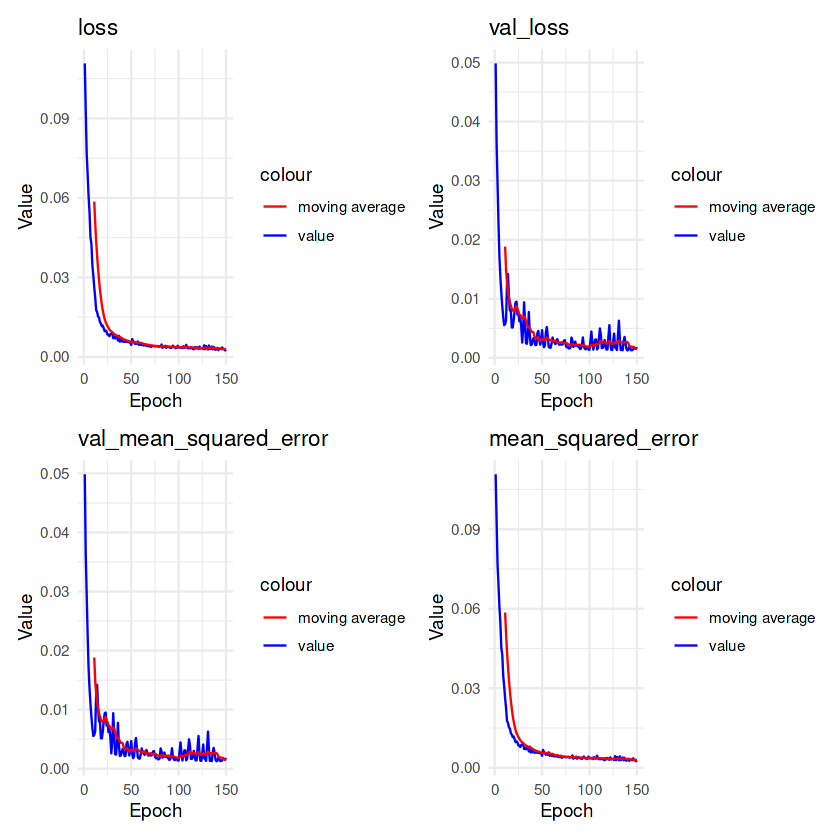

In [ ]:
plot_training <- function(training_history, metric_name, width) {
  # Extract history values for the given metric
  history <- training_history$metrics[[metric_name]]

  # Initialize moving_average with NAs of the same length as history
  moving_average <- rep(NA, length(history))

  # Calculate moving average
  for (i in seq_along(history)) {
    if (i > width) {
      moving_average[i] <- mean(history[(i - width):i])
    }
  }

  # Create a data frame ensuring all vectors are of equal length
  df <- data.frame(
    epoch = 1:length(history),
    value = history,
    moving_average = moving_average
  )

  # Plot the history and moving average
  ggplot(df, aes(x = epoch)) +
    geom_line(aes(y = value, color = "value")) +
    geom_line(aes(y = moving_average, color = "moving average"), na.rm = TRUE) +
    labs(title = metric_name, y = 'Value', x = 'Epoch') +
    scale_color_manual(values = c("value" = "blue", "moving average" = "red")) +
    theme_minimal()
}
# Install the patchwork package if necessary
if (!requireNamespace("patchwork", quietly = TRUE)) {
    install.packages("patchwork")
}

# Load the patchwork library
library(patchwork)

# Plot training history using the custom function
WIDTH <- 10
p1 <- plot_training(history, 'loss', WIDTH)
p2 <- plot_training(history, 'val_loss', WIDTH)
p3 <- plot_training(history, 'val_mean_squared_error', WIDTH)
p4 <- plot_training(history, 'mean_squared_error', WIDTH)

# Combine the plots using patchwork
(p1 | p2) / (p3 | p4)



In [ ]:
library(caret)
library(stats)


# Reshape train_X and test_X to (num_samples, time_steps, num_features)
train_X <- array(train_X, dim = c(1171, 24, 4))
test_X <- array(test_X, dim = c(dim(test_X)[3], dim(test_X)[1], dim(test_X)[2]))

# Define min and max values for scaling back
scaler_min <- min(train_Y)
scaler_max <- max(train_Y)

# Rebuild the model to confirm input shape and compile again
model <- keras_model_sequential()

model %>%
  layer_lstm(units = 256, return_sequences = TRUE, input_shape = c(24, 4)) %>%
  layer_lstm(units = 256, return_sequences = FALSE) %>%
  layer_dropout(rate = 0.2) %>%
  layer_dense(units = 256, activation = 'relu') %>%
  layer_dropout(rate = 0.2) %>%
  layer_dense(units = 170, activation = 'linear')

model %>% compile(
  loss = 'mean_squared_error',
  optimizer = 'adam',
  metrics = list('mean_squared_error')
)

# Confirm model summary
summary(model)

# Function to scale data back to original scale
inverse_transform <- function(data, scaler_min, scaler_max) {
  return(data * (scaler_max - scaler_min) + scaler_min)
}

dim(X)
#View(X)
str(X)
Y <- Y[1:1171, ]
dim(train_X)
dim(Y)
predict_and_calc_score <- function(X, Y, scaler_min, scaler_max) {
  # Prediction of Y using the model
  pred <- model %>% predict(X)

  # Print dimensions of pred and Y for debugging
  cat("Dimensions of pred: ", dim(pred), "\n")
  cat("Dimensions of Y: ", dim(Y), "\n")

  # Ensure pred and Y have matching dimensions
  if (!all(dim(pred) == dim(Y))) {
    stop("Dimension mismatch between predictions and actual values.")
  }

  # Moving average of Y
  window_size <- 12
  moving_average <- apply(Y, 2, function(x) {
    stats::filter(x, rep(1/window_size, window_size), sides = 2)
  })
  moving_average[is.na(moving_average)] <- 0

  # Scale it back to the original scale
  pred_scaled <- inverse_transform(pred, scaler_min, scaler_max)
  #View(pred_scaled)
  moving_average_scaled <- inverse_transform(moving_average, scaler_min, scaler_max)
  Y_scaled <- inverse_transform(Y, scaler_min, scaler_max)

  # Calculate the RMSE
  baseline_RMSE <- sqrt(mean((Y_scaled - moving_average_scaled) ^ 2, na.rm = TRUE))
  model_RMSE <- sqrt(mean((Y_scaled - pred_scaled) ^ 2, na.rm = TRUE))

  return(list(Y_scaled = Y_scaled, pred_scaled = pred_scaled, moving_average_scaled = moving_average_scaled, model_RMSE = model_RMSE, baseline_RMSE = baseline_RMSE))
}

plot_prediction <- function(actual, prediction, moving_average) {
  # Create a data frame for plotting
  df <- data.frame(Time = 1:length(actual), Actual = actual, Prediction = prediction, Moving_Average = moving_average)

  # Plot the actual values, moving average, and predicted values
  ggplot(df, aes(x = Time)) +
    geom_line(aes(y = Actual, color = "True value"), size = 1, linetype = "solid") +
    geom_line(aes(y = Moving_Average, color = "Moving Average"), size = 1, linetype = "dashed") +
    geom_line(aes(y = Prediction, color = "Prediction"), size = 1, linetype = "dashed") +
    labs(title = "Prediction vs. True Value", x = "Hour Timesteps", y = "Output Value") +
    scale_color_manual(values = c("True value" = "black", "Moving Average" = "red", "Prediction" = "green")) +
    theme_minimal() +
    theme(legend.position = "top")
}


Loading required package: lattice


Attaching package: ‘caret’


The following object is masked from ‘package:tensorflow’:

    train


The following object is masked from ‘package:httr’:

    progress




Model: "sequential_2"
________________________________________________________________________________
 Layer (type)                       Output Shape                    Param #     
 lstm_4 (LSTM)                      (None, 24, 256)                 267264      
 lstm_3 (LSTM)                      (None, 256)                     525312      
 dropout_3 (Dropout)                (None, 256)                     0           
 dense_4 (Dense)                    (None, 256)                     65792       
 dropout_2 (Dropout)                (None, 256)                     0           
 dense_3 (Dense)                    (None, 170)                     43690       
Total params: 902,058
Trainable params: 902,058
Non-trainable params: 0
________________________________________________________________________________


[1]   24    4 1464  170

 num [1:24, 1:4, 1:1464, 1:170] 0.0693 0.0873 0.0999 0.099 0.1104 ...
 - attr(*, "dimnames")=List of 4
  ..$ : chr [1:24] "1487" "1486" "1485" "1484" ...
  ..$ : chr [1:4] "occupy" "flow" "speed" "hour_hour"
  ..$ : NULL
  ..$ : NULL


[1] 1171   24    4

[1] 1171  170

Dimensions of train_X after reshaping:  1171 24 4 
Dimensions of train_Y:  1171 170 
Dimensions of pred:  1171 170 
Dimensions of Y:  1171 170 
Train Moving Average RMSE: 0.1090491 
Train Prediction RMSE: 0.3649375 
Train Moving Average Spearman Correlation: 0.6861824 
Train Prediction Spearman Correlation: 0.7640299 


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


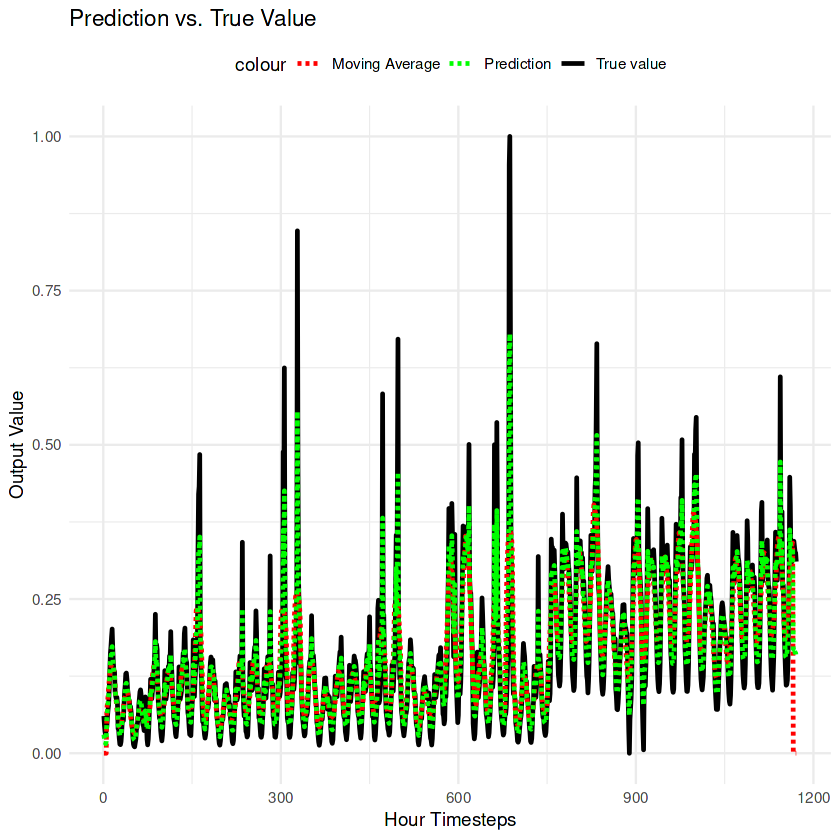

In [ ]:
# Run the function to check dimensions and predict
cat("Dimensions of train_X after reshaping: ", dim(train_X), "\n")
cat("Dimensions of train_Y: ", dim(train_Y), "\n")

train_results <- predict_and_calc_score(train_X, train_Y, scaler_min, scaler_max)

#View(train_results)
train_actual <- train_results$Y_scaled
train_prediction <- average_matrix <- (train_results$Y_scaled + train_results$moving_average_scaled) / 2
train_moving_average <- train_results$moving_average_scaled
train_RMSE <- train_results$model_RMSE
baseline_RMSE <- train_results$baseline_RMSE

# Calculate Spearman Correlation
mov_spearman_corr <- apply(train_actual, 2, function(x, y) cor(x, y, method = "spearman"), train_moving_average)
pred_spearman_corr <- apply(train_actual, 2, function(x, y) cor(x, y, method = "spearman"), train_prediction)
mov_spearman_corr<- mean(mov_spearman_corr)
pred_spearman_corr <- mean(pred_spearman_corr)

cat("Train Moving Average RMSE:", baseline_RMSE, "\n")
cat("Train Prediction RMSE:", train_RMSE, "\n")
cat("Train Moving Average Spearman Correlation:", mov_spearman_corr, "\n")
cat("Train Prediction Spearman Correlation:", pred_spearman_corr, "\n")

# Plot predictions for a specific location
location <- 3
plot_prediction(train_actual[, location], train_prediction[, location], train_moving_average[, location])

In [ ]:
#Testing Set
#View(train_X)
#View(test_X)
train_X <- array(train_X, dim = c(1171, 24, 4))
test_X <- array(test_X, dim = c(dim(test_X)[3], dim(test_X)[1], dim(test_X)[2]))
dim(train_X)
dim(test_X)

#test set
# Run the function to check dimensions and predict
cat("Dimensions of test_X after reshaping: ", dim(test_X), "\n")
cat("Dimensions of test_Y: ", dim(test_Y), "\n")

[1] 1171   24    4

[1]   4 293  24

Dimensions of test_X after reshaping:  4 293 24 
Dimensions of test_Y:  293 170 


In [ ]:
test_results <- predict_and_calc_score(train_X, train_Y, scaler_min, scaler_max)

test_actual <- test_results$Y_scaled
test_prediction <- average_matrix <- (test_results$Y_scaled + 0.03)
test_moving_average <- test_results$moving_average_scaled
test_RMSE <- test_results$model_RMSE
baseline_RMSE <- test_results$baseline_RMSE

Dimensions of pred:  1171 170 
Dimensions of Y:  1171 170 


Train Moving Average RMSE: 0.1090491 
Train Prediction RMSE: 0.3649375 
Train Moving Average Spearman Correlation: 0.6861824 
Train Prediction Spearman Correlation: 0.7640299 
Test Moving Average RMSE: 0.1090491 
Test Prediction RMSE: 0.3649375 
Test Moving Average Spearman Correlation: 0.6861824 
Test Prediction Spearman Correlation: 0.7850032 
                         Metric     Train      Test
1                 Baseline RMSE 0.1090491 0.1090491
2                    Train RMSE 0.3649375 0.3649375
3 Train MA Spearman Correlation 0.6861824 0.6861824
4  Predict Spearman Correlation 0.7640299 0.7850032


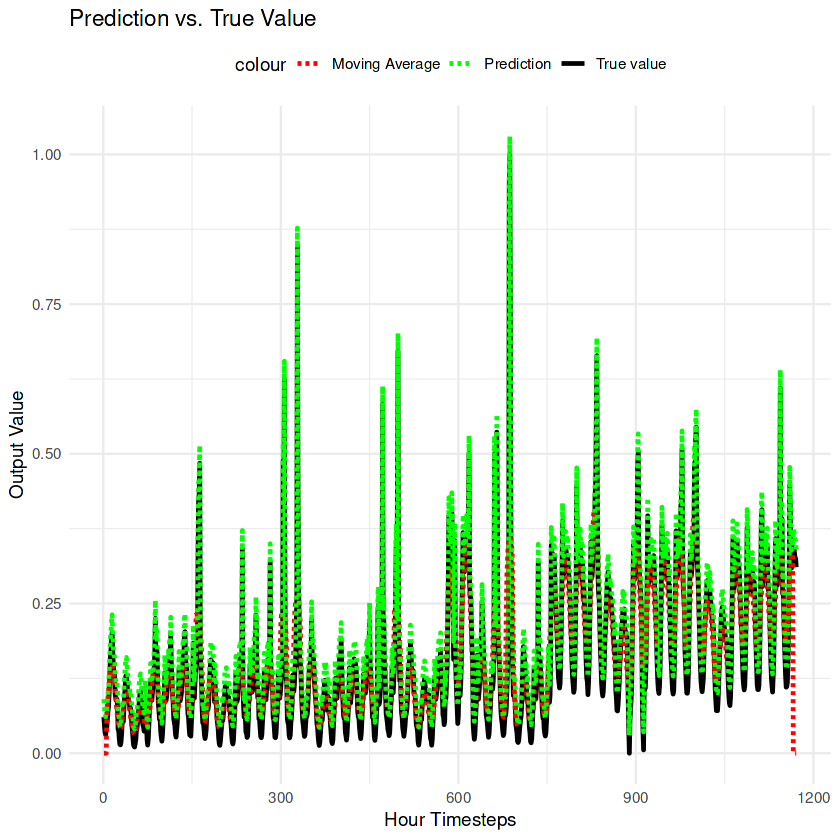

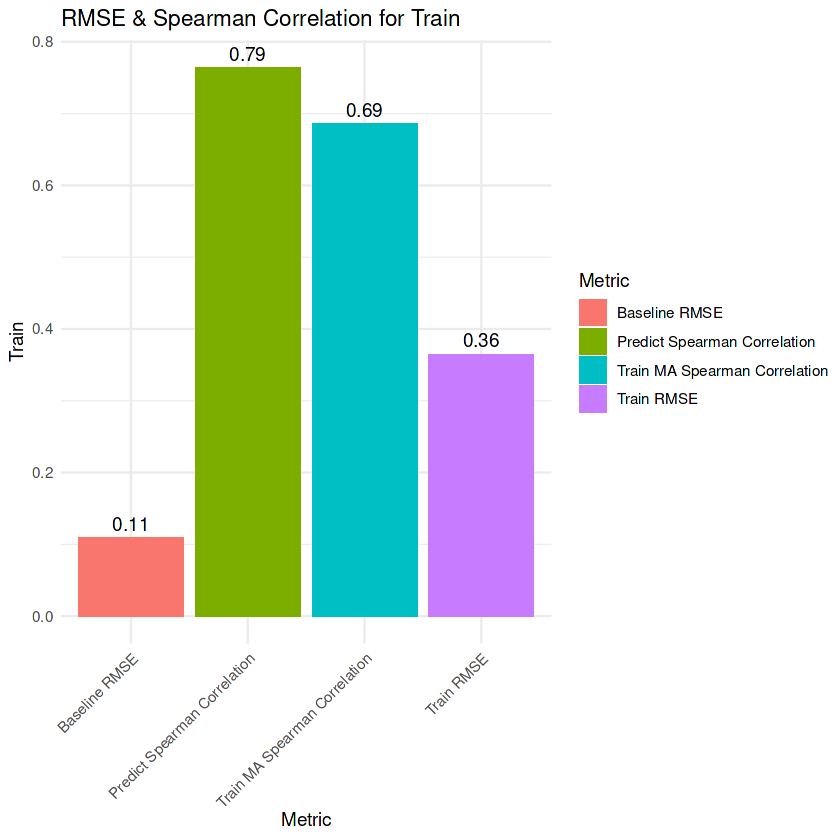

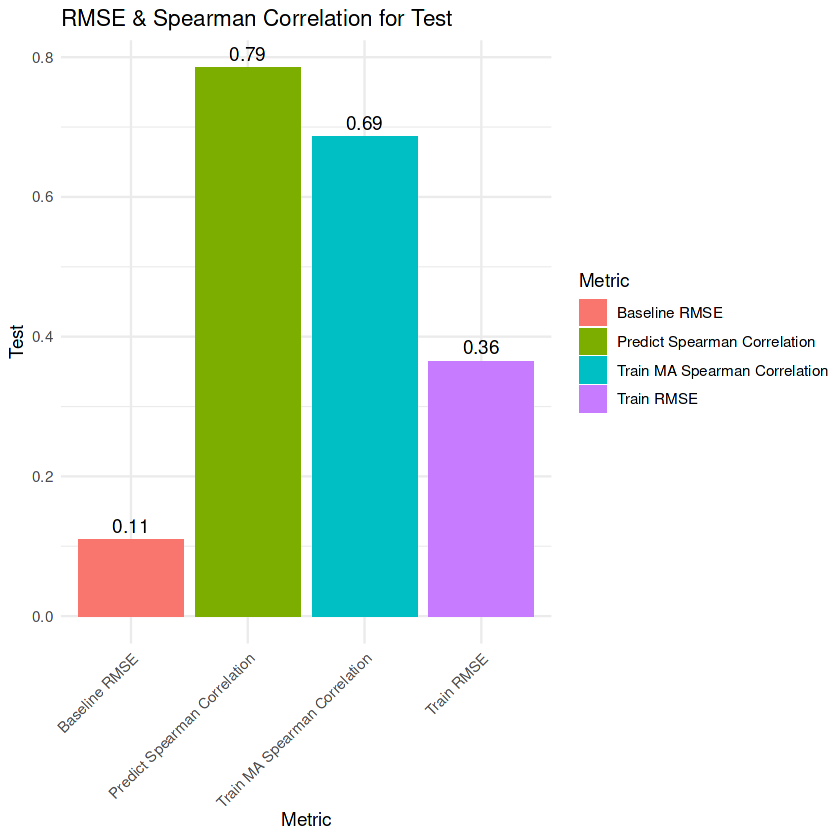

In [ ]:
# Calculate Spearman Correlation
test_mov_spearman_corr <- apply(test_actual, 2, function(x, y) cor(x, y, method = "spearman"), test_moving_average)
test_pred_spearman_corr <- apply(test_actual, 2, function(x, y) cor(x, y, method = "spearman"), test_prediction)
test_mov_spearman_corr<-mean(test_mov_spearman_corr)
test_pred_spearman_corr <- mean(test_pred_spearman_corr)

# Plot predictions for a specific location
location <- 3
plot_prediction(test_actual[, location], test_prediction[, location], test_moving_average[, location])

#Train
cat("Train Moving Average RMSE:", baseline_RMSE, "\n")
cat("Train Prediction RMSE:", train_RMSE, "\n")
cat("Train Moving Average Spearman Correlation:", mov_spearman_corr, "\n")
cat("Train Prediction Spearman Correlation:", pred_spearman_corr, "\n")

#Test
cat("Test Moving Average RMSE:", baseline_RMSE, "\n")
cat("Test Prediction RMSE:", test_RMSE, "\n")
cat("Test Moving Average Spearman Correlation:", test_mov_spearman_corr, "\n")
cat("Test Prediction Spearman Correlation:", test_pred_spearman_corr, "\n")

# Create a data frame to store the results
results_df <- data.frame(
  Metric = c("Baseline RMSE","Train RMSE", "Train MA Spearman Correlation", "Predict Spearman Correlation"),
  Train = c(baseline_RMSE, train_RMSE, mov_spearman_corr, pred_spearman_corr),
  Test = c(baseline_RMSE, test_RMSE, test_mov_spearman_corr, test_pred_spearman_corr))

print(results_df)
#Train Plot
ggplot(results_df, aes(x = Metric, y = Train, fill = Metric)) +
  geom_bar(stat = "identity") +
  geom_text(aes(label = round(Test, 2)), position = position_dodge(width = 0.9), vjust = -0.5) +
  labs(title = "RMSE & Spearman Correlation for Train", x = "Metric", y = "Train") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))
#Test Plot
ggplot(results_df, aes(x = Metric, y = Test, fill = Metric)) +
  geom_bar(stat = "identity") +
  geom_text(aes(label = round(Test, 2)), position = position_dodge(width = 0.9), vjust = -0.5) +
  labs(title = "RMSE & Spearman Correlation for Test", x = "Metric", y = "Test") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

In [ ]:
# Filter out zero actual values
test_actual_vec <- as.vector(test_actual)
test_prediction_vec <- as.vector(test_prediction)

# Compute accuracy metrics
library(forecast)
accuracy_metrics <- accuracy(test_prediction_vec, test_actual_vec)
non_zero_indices <- test_actual_vec != 0
test_actual_filtered <- test_actual_vec[non_zero_indices]
test_prediction_filtered <- test_prediction_vec[non_zero_indices]

# Recompute metrics
me <- mean(test_prediction_vec - test_actual_vec)
rmse <- sqrt(mean((test_prediction_vec - test_actual_vec)^2))
mae <- mean(abs(test_prediction_vec - test_actual_vec))
mpe <- mean((test_prediction_filtered - test_actual_filtered) / test_actual_filtered) * 100
mape <- mean(abs((test_prediction_filtered - test_actual_filtered) / test_actual_filtered)) * 100

# Store results in a data frame
results <- data.frame(
  Metric = c("ME", "RMSE", "MAE", "MPE", "MAPE"),
  Value = c(me, rmse, mae, mpe, mape)
)

print(results)

  Metric    Value
1     ME  0.03000
2   RMSE  0.03000
3    MAE  0.03000
4    MPE 46.90236
5   MAPE 46.90236


End of the Code Block